In [2]:
# Cell 1.1: Thiết lập môi trường, seed và cấu trúc thư mục cho NB02 (Đã sửa lỗi Windows FAISS)
import os
import sys
import json
import random
import subprocess
import numpy as np
import pandas as pd
import sklearn

# 1. Danh mục các gói phụ thuộc và tên module import tương ứng
dependencies = {
    "pypdf": "pypdf",
    "sentence-transformers": "sentence_transformers",
    "faiss-cpu": "faiss"
}

# 2. Kiểm tra và tự động cài đặt gói còn thiếu
for pkg_install, mod_import in dependencies.items():
    try:
        __import__(mod_import)
    except ImportError:
        print(f"Đang cài đặt thư viện {pkg_install}...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_install])
            __import__(mod_import)
            print(f"-> Cài đặt thành công {pkg_install}")
        except Exception as e:
            if pkg_install == "faiss-cpu":
                print(f"[Lưu ý môi trường Windows] Không thể cài faiss-cpu qua pip ({e}).")
                print("-> Hệ thống sẽ kích hoạt bộ chỉ mục tương đương FAISS IndexFlatIP bằng NumPy/Scikit-learn.")
            else:
                raise e

# 3. Kiểm tra tính sẵn sàng của FAISS
try:
    import faiss
    HAS_FAISS = True
except ImportError:
    HAS_FAISS = False

import pypdf
import sentence_transformers

# 4. Cố định Random Seed trên toàn hệ thống
SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# 5. Khởi tạo cấu trúc thư mục lưu trữ cho NB02
NB02_DIRS = [
    "documents",
    "outputs/kb_index",
    "outputs/figures",
    "outputs/metrics"
]
for d in NB02_DIRS:
    os.makedirs(d, exist_ok=True)

# 6. Ghi nhận thông tin môi trường
print("\n=== THÔNG TIN MÔI TRƯỜNG THỰC THI NOTEBOOK 02 (RAG & KB) ===")
print(f"Python version              : {sys.version.split()[0]}")
print(f"pypdf version               : {pypdf.__version__}")
print(f"sentence-transformers ver   : {sentence_transformers.__version__}")
print(f"FAISS Engine                : {'Faiss C++ Native' if HAS_FAISS else 'NumPy VectorStore (IndexFlatIP Equivalent)'}")
print(f"Scikit-learn version        : {sklearn.__version__}")
print(f"Trạng thái                  : Đã sẵn sàng thư mục lưu trữ và cố định SEED = {SEED}.")

D:\ANACONDA\Lib\site-packages\pypdf\_crypt_providers\_cryptography.py:32: CryptographyDeprecationWarning: ARC4 has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.ARC4 and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  from cryptography.hazmat.primitives.ciphers.algorithms import AES, ARC4


Đang cài đặt thư viện faiss-cpu...
-> Cài đặt thành công faiss-cpu

=== THÔNG TIN MÔI TRƯỜNG THỰC THI NOTEBOOK 02 (RAG & KB) ===
Python version              : 3.11.16
pypdf version               : 4.2.0
sentence-transformers ver   : 2.7.0
FAISS Engine                : Faiss C++ Native
Scikit-learn version        : 1.9.0
Trạng thái                  : Đã sẵn sàng thư mục lưu trữ và cố định SEED = 42.


In [3]:
# Cell 1.2: Chuẩn bị kho tài liệu nguồn y khoa lâm sàng chuẩn hóa
corpus_definitions = [
    {
        "doc_id": "DOC_01_ADA_DIAGNOSIS",
        "filename": "doc_01_ada_standards_diagnosis.md",
        "title": "ADA Standards of Care - Phân loại và Tiêu chuẩn chẩn đoán Đái tháo đường",
        "author_org": "American Diabetes Association (ADA)",
        "content": """# ADA Standards of Care: Phân loại và Tiêu chuẩn chẩn đoán Đái tháo đường

## Mục 1. Tiêu chuẩn xác định đái tháo đường lâm sàng
Hiệp hội Đái tháo đường Hoa Kỳ (ADA) quy định tiêu chuẩn chẩn đoán đái tháo đường dựa trên một trong bốn tiêu chí cận lâm sàng sau:
1. Chỉ số HbA1c >= 6.5% (48 mmol/mol), thực hiện bằng phương pháp chuẩn hóa theo NGSP.
2. Nồng độ glucose huyết tương lúc đói (Fasting Plasma Glucose - FPG) >= 126 mg/dL (7.0 mmol/L) sau nhịn ăn ít nhất 8 giờ.
3. Nồng độ glucose huyết tương 2 giờ sau nghiệm pháp dung nạp glucose đường uống 75g (OGTT) >= 200 mg/dL (11.1 mmol/L).
4. Ở bệnh nhân có triệu chứng kinh điển của tăng đường huyết cấp tính (uống nhiều, tiểu nhiều, ăn nhiều, sút cân không rõ nguyên nhân), nồng độ glucose huyết tương ngẫu nhiên >= 200 mg/dL (11.1 mmol/L).

## Mục 2. Tiêu chuẩn xác định tiền đái tháo đường (Prediabetes)
Tiền đái tháo đường là tình trạng rối loạn chuyển hóa glucose chưa đạt ngưỡng đái tháo đường nhưng mang nguy cơ tiến triển thành bệnh và biến chứng tim mạch cao:
- Rối loạn đường huyết lúc đói (IFG): Glucose huyết tương lúc đói từ 100 đến 125 mg/dL (5.6 - 6.9 mmol/L).
- Rối loạn dung nạp glucose (IGT): Glucose huyết tương 2 giờ sau nghiệm pháp OGTT từ 140 đến 199 mg/dL (7.8 - 11.0 mmol/L).
- Chỉ số HbA1c nằm trong khoảng từ 5.7% đến 6.4% (39 - 47 mmol/mol).
"""
    },
    {
        "doc_id": "DOC_02_MOH_VN_GUIDELINE",
        "filename": "doc_02_moh_vn_type2_guideline.md",
        "title": "Hướng dẫn chẩn đoán và điều trị đái tháo đường típ 2 - Bộ Y tế Việt Nam",
        "author_org": "Bộ Y tế Việt Nam",
        "content": """# Hướng dẫn Chẩn đoán và Điều trị Đái tháo đường típ 2 - Bộ Y tế Việt Nam

## Mục 1. Mục tiêu kiểm soát đường huyết cá nhân hóa
Mục tiêu điều trị chung cho người trưởng thành không mang thai:
- Chỉ số HbA1c: < 7.0% (53 mmol/mol) nhằm giảm biến chứng vi mạch và mạch máu lớn.
- Glucose huyết tương lúc đói và trước các bữa ăn: 80 - 130 mg/dL (4.4 - 7.2 mmol/L).
- Glucose huyết tương đỉnh sau ăn 1 đến 2 giờ: < 180 mg/dL (< 10.0 mmol/L).
Mục tiêu HbA1c có thể nới lỏng mức an toàn (< 8.0%) đối với bệnh nhân cao tuổi, thời gian mắc bệnh kéo dài, có tiền sử hạ đường huyết nặng hoặc mang nhiều bệnh nền nghiêm trọng.

## Mục 2. Kiểm soát huyết áp và mỡ máu đi kèm
- Huyết áp mục tiêu cho bệnh nhân đái tháo đường có tăng huyết áp là < 130/80 mmHg nếu dung nạp tốt, hoặc < 140/90 mmHg.
- Nhóm thuốc hạ áp ưu tiên hàng đầu là thuốc ức chế men chuyển (ACEi) hoặc ức chế thụ thể angiotensin (ARB), đặc biệt trên bệnh nhân có albumin niệu.
- Điều trị rối loạn lipid máu bằng thuốc nhóm Statin nhằm đạt mục tiêu hạ LDL-cholesterol theo từng phân tầng nguy cơ tim mạch.
"""
    },
    {
        "doc_id": "DOC_03_WHO_SCREENING",
        "filename": "doc_03_who_screening_prevention.md",
        "title": "WHO Guidelines - Sàng lọc nguy cơ và dự phòng đái tháo đường",
        "author_org": "World Health Organization (WHO)",
        "content": """# Tổ chức Y tế Thế giới (WHO): Sàng lọc và Dự phòng Đái tháo đường

## Mục 1. Đối tượng nguy cơ cao cần sàng lọc định kỳ
Sàng lọc đái tháo đường típ 2 nên được thực hiện ở mọi cá nhân từ 35 tuổi trở lên, hoặc người ở bất kỳ lứa tuổi nào có kèm các yếu tố nguy cơ:
- Thừa cân hoặc béo phì: Chỉ số khối cơ thể (BMI) >= 23 kg/m² đối với người châu Á (hoặc >= 25 kg/m² đối với các chủng tộc khác).
- Tiền sử gia đình có người trực hệ (bố, mẹ, anh chị em ruột) mắc đái tháo đường.
- Lối sống tĩnh tại, ít hoạt động thể lực.
- Tiền sử tăng huyết áp (huyết áp >= 140/90 mmHg hoặc đang điều trị thuốc hạ áp).
- Tiền sử rối loạn lipid máu (HDL-C < 35 mg/dL hoặc Triglyceride > 250 mg/dL).
- Phụ nữ có tiền sử đái tháo đường thai kỳ hoặc hội chứng buồng trứng đa nang (PCOS).

## Mục 2. Can thiệp dự phòng chủ động
Ở người tiền đái tháo đường, can thiệp thay đổi lối sống tích cực giúp giảm trên 50% nguy cơ tiến triển thành bệnh:
- Giảm ít nhất 5% đến 7% trọng lượng cơ thể nếu có thừa cân, béo phì.
- Duy trì hoạt động thể lực cường độ trung bình tối thiểu 150 phút mỗi tuần (như đi bộ nhanh, đạp xe).
"""
    },
    {
        "doc_id": "DOC_04_NIDDK_HYPOGLYCEMIA",
        "filename": "doc_04_niddk_hypoglycemia_emergency.md",
        "title": "NIDDK Guidelines - Nhận diện hạ đường huyết cấp và quy tắc xử trí khẩn cấp",
        "author_org": "National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK)",
        "content": """# NIDDK: Nhận diện và Xử trí Hạ đường huyết cấp tính

## Mục 1. Định nghĩa và Triệu chứng hạ đường huyết
Hạ đường huyết (Hypoglycemia) xảy ra khi nồng độ glucose trong máu giảm xuống dưới 70 mg/dL (3.9 mmol/L).
Triệu chứng cảnh báo sớm bao gồm:
- Run rẩy tay chân, vã mồ hôi lạnh, hồi hộp đánh trống ngực.
- Chóng mặt, đau đầu, cồn cào, đói dữ dội.
- Mắt nhìn mờ, lo âu, bồn chồn, da tái nhợt.
Nếu không được xử trí kịp thời, đường huyết giảm sâu (< 54 mg/dL) có thể dẫn đến lú lẫn, co giật, hôn mê và đe dọa tính mạng.

## Mục 2. Quy tắc 15-15 trong xử trí hạ đường huyết
Khi bệnh nhân còn tỉnh táo và đo đường huyết < 70 mg/dL, áp dụng ngay Quy tắc 15-15:
1. Dùng ngay 15 gram carbohydrate tác dụng nhanh: uống 1/2 cốc nước ép trái cây (khoảng 120ml), 1/2 lon nước ngọt có đường thông thường, hoặc ngậm 3-4 viên đường/kẹo.
2. Nghỉ ngơi tại chỗ và đợi trong 15 phút.
3. Đo lại đường huyết mao mạch sau 15 phút:
   - Nếu đường huyết vẫn dưới 70 mg/dL: tiếp tục nạp thêm 15 gram carbohydrate và đợi thêm 15 phút.
   - Nếu đường huyết đã >= 70 mg/dL: bệnh nhân nên ăn một bữa ăn phụ nhẹ (chứa tinh bột phức hợp và protein) nếu bữa ăn chính tiếp theo cách xa hơn 1 giờ.
"""
    },
    {
        "doc_id": "DOC_05_ADA_LIFESTYLE",
        "filename": "doc_05_ada_lifestyle_management.md",
        "title": "ADA Lifestyle Management - Khuyến cáo dinh dưỡng và vận động thể lực",
        "author_org": "American Diabetes Association (ADA)",
        "content": """# ADA: Khuyến cáo Dinh dưỡng và Vận động thể lực cho bệnh nhân đái tháo đường

## Mục 1. Nguyên tắc dinh dưỡng và xây dựng khẩu phần
- Kiểm soát tổng năng lượng nạp vào để duy trì hoặc giảm cân nặng hợp lý.
- Áp dụng nguyên tắc Đĩa thức ăn lành mạnh (Diabetes Plate Method):
  + 1/2 đĩa là các loại rau củ không chứa tinh bột (rau cải, súp lơ, dưa leo, cà chua).
  + 1/4 đĩa là nguồn protein nạc (cá, ức gà, trứng, đậu đỗ).
  + 1/4 đĩa là nguồn carbohydrate phức hợp giàu chất xơ (gạo lứt, yến mạch, khoai lang).
- Hạn chế tối đa đường tự do, bánh kẹo ngọt, nước ngọt có ga và các sản phẩm bột tinh chế.
- Khuyến nghị lượng chất xơ tiêu thụ từ 14 gram trên mỗi 1000 kcal nạp vào (tương đương 25 - 35 gram chất xơ mỗi ngày).

## Mục 2. Khuyến nghị hoạt động thể lực
- Vận động nhịp điệu (Aerobic): Tối thiểu 150 phút mỗi tuần với cường độ trung bình (đi bộ nhanh, bơi lội, khiêu vũ), chia đều ít nhất 3 ngày trong tuần và không nghỉ quá 2 ngày liên tiếp.
- Bài tập kháng lực (Resistance training): Thực hiện 2 đến 3 buổi mỗi tuần vào các ngày không liên tiếp nhằm tăng cường độ nhạy insulin của khối cơ.
- Giảm thiểu thời gian ngồi tĩnh tại: Đứng dậy đi lại nhẹ nhàng sau mỗi 30 phút ngồi làm việc liên tục.
"""
    },
    {
        "doc_id": "DOC_06_MOH_SAFETY_COMPLICATIONS",
        "filename": "doc_06_moh_safety_and_complications.md",
        "title": "Bộ Y tế - Theo dõi biến chứng mạn tính và cảnh báo an toàn điều trị",
        "author_org": "Bộ Y tế Việt Nam",
        "content": """# Bộ Y tế Việt Nam: Theo dõi Biến chứng mạn tính và Nguyên tắc An toàn Điều trị

## Mục 1. Tầm soát định kỳ các biến chứng mạn tính
Bệnh nhân đái tháo đường típ 2 cần được tầm soát định kỳ hàng năm các biến chứng:
- Biến chứng mắt (Bệnh võng mạc đái tháo đường): Khám đáy mắt giãn đồng tử định kỳ tối thiểu 1 lần mỗi năm bởi bác sĩ chuyên khoa mắt.
- Biến chứng thận: Xét nghiệm tỷ lệ Albumin/Creatinine niệu (UACR) và ước tính mức lọc cầu thận (eGFR) ít nhất mỗi năm một lần.
- Biến chứng thần kinh và bàn chân: Khám bàn chân toàn diện hàng năm bằng monofilament 10g để phát hiện giảm cảm giác bảo vệ; tự kiểm tra bàn chân mỗi ngày để phát hiện vết loét, nứt nẻ.
- Biến chứng tim mạch: Đo điện tâm đồ, kiểm tra huyết áp mỗi lần tái khám và tầm soát bệnh động mạch ngoại biên.

## Mục 2. Nguyên tắc an toàn y tế và giới hạn của hệ thống tư vấn AI
- Bệnh nhân tuyệt đối KHÔNG tự ý ngừng thuốc, giảm liều hoặc tự thay đổi phác đồ thuốc hạ đường huyết (Metformin, Sulfonylurea, SGLT2i, GLP-1 RA, Insulin) mà không có chỉ định trực tiếp từ bác sĩ chuyên khoa.
- Mọi khuyến nghị của hệ thống trí tuệ nhân tạo chỉ mang tính chất giáo dục sức khỏe và hỗ trợ tham khảo lối sống. Khi xuất hiện dấu hiệu cấp tính (sốt cao, sốt rét, nôn liên tục, khó thở, thở mùi táo chín, đường huyết đo được > 300 mg/dL hoặc < 70 mg/dL không hồi phục), bệnh nhân phải liên hệ cơ sở y tế gần nhất ngay lập tức.
"""
    }
]

# Ghi các tài liệu vào thư mục documents/
created_count = 0
for doc in corpus_definitions:
    fpath = os.path.join("documents", doc["filename"])
    with open(fpath, "w", encoding="utf-8") as f:
        f.write(doc["content"])
    created_count += 1

print(f"Đã chuẩn bị thành công {created_count} tài liệu y khoa nguồn trong thư mục documents/.")

Đã chuẩn bị thành công 6 tài liệu y khoa nguồn trong thư mục documents/.


In [4]:
# Cell 1.3: Hàm đọc và làm sạch tài liệu đa định dạng (PDF, MD, TXT) bảo toàn Metadata
import re
import os
import pypdf

def clean_text_content(text: str) -> str:
    """Loại bỏ ký tự nhiễu, chuẩn hóa khoảng trắng và dòng trống."""
    text = re.sub(r'\r\n', '\n', text)
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

def load_and_preprocess_documents(doc_directory: str = "documents"):
    """
    Đọc tất cả các tệp PDF, MD, TXT trong thư mục, làm sạch và gắn metadata nguồn.
    Hỗ trợ cả trường hợp sinh viên tải tệp PDF thực tế lên thư mục documents/.
    """
    loaded_docs = []
    supported_extensions = [".pdf", ".md", ".txt"]
    
    file_list = sorted(os.listdir(doc_directory))
    for fname in file_list:
        fpath = os.path.join(doc_directory, fname)
        if not os.path.isfile(fpath):
            continue
            
        ext = os.path.splitext(fname)[1].lower()
        if ext not in supported_extensions:
            continue
            
        base_name = os.path.splitext(fname)[0].upper()
        
        # 1. Đọc tệp PDF
        if ext == ".pdf":
            try:
                reader = pypdf.PdfReader(fpath)
                for page_idx, page in enumerate(reader.pages):
                    raw_page = page.extract_text() or ""
                    clean_page = clean_text_content(raw_page)
                    if len(clean_page) > 20:
                        loaded_docs.append({
                            "doc_id": f"{base_name}_P{page_idx+1:02d}",
                            "source_file": fname,
                            "section_or_page": f"Trang {page_idx+1}",
                            "file_type": "PDF",
                            "text": clean_page,
                            "char_count": len(clean_page),
                            "word_count": len(clean_page.split())
                        })
            except Exception as e:
                print(f"[Cảnh báo] Lỗi khi đọc file PDF {fname}: {e}")
                
        # 2. Đọc tệp Markdown hoặc Text
        elif ext in [".md", ".txt"]:
            with open(fpath, "r", encoding="utf-8") as f:
                raw_text = f.read()
            cleaned_text = clean_text_content(raw_text)
            
            # Tách các mục theo tiêu đề Markdown (##) để bảo toàn ngữ nghĩa
            sections = re.split(r'\n(?=##?\s+)', cleaned_text)
            for s_idx, sec in enumerate(sections):
                sec_str = sec.strip()
                if not sec_str:
                    continue
                first_line = sec_str.split("\n")[0].replace("#", "").strip()
                title_label = first_line[:50] if first_line else f"Phần {s_idx+1}"
                
                loaded_docs.append({
                    "doc_id": f"{base_name}_S{s_idx+1:02d}",
                    "source_file": fname,
                    "section_or_page": f"Mục {s_idx+1}: {title_label}",
                    "file_type": ext.upper().replace(".", ""),
                    "text": sec_str,
                    "char_count": len(sec_str),
                    "word_count": len(sec_str.split())
                })
                
    return loaded_docs

print("Đã định nghĩa thành công hàm load_and_preprocess_documents().")

Đã định nghĩa thành công hàm load_and_preprocess_documents().


In [5]:
# Cell 1.4: Nạp toàn bộ tài liệu nguồn và kiểm kê siêu dữ liệu (Metadata Inventory)
raw_documents = load_and_preprocess_documents("documents")

if len(raw_documents) == 0:
    raise ValueError("Không tìm thấy tài liệu hợp lệ trong thư mục documents/!")

# Tổng hợp DataFrame kiểm tra chất lượng
df_inventory = pd.DataFrame(raw_documents)

print(f"=== TỔNG HỢP KHO TÀI LIỆU NGUỒN ({len(raw_documents)} PHẦN TÀI LIỆU) ===")
display_cols = ["doc_id", "source_file", "file_type", "section_or_page", "char_count", "word_count"]
display(df_inventory[display_cols])

print(f"\nTổng số ký tự văn bản: {df_inventory['char_count'].sum():,} ký tự")
print(f"Tổng số từ (Words)   : {df_inventory['word_count'].sum():,} từ")
print(f"Độ dài trung bình mỗi mục: {df_inventory['word_count'].mean():.1f} từ")

=== TỔNG HỢP KHO TÀI LIỆU NGUỒN (18 PHẦN TÀI LIỆU) ===


,doc_id,source_file,file_type,section_or_page,char_count,word_count
0,DOC_01_ADA_STANDARDS_DIAGNOSIS_S01,doc_01_ada_standards_diagnosis.md,MD,Mục 1: ADA Standards of Care: Phân loại và Tiê...,73,15
1,DOC_01_ADA_STANDARDS_DIAGNOSIS_S02,doc_01_ada_standards_diagnosis.md,MD,Mục 2: Mục 1. Tiêu chuẩn xác định đái tháo đườ...,718,144
2,DOC_01_ADA_STANDARDS_DIAGNOSIS_S03,doc_01_ada_standards_diagnosis.md,MD,Mục 3: Mục 2. Tiêu chuẩn xác định tiền đái thá...,525,106
3,DOC_02_MOH_VN_TYPE2_GUIDELINE_S01,doc_02_moh_vn_type2_guideline.md,MD,Mục 1: Hướng dẫn Chẩn đoán và Điều trị Đái thá...,73,19
4,DOC_02_MOH_VN_TYPE2_GUIDELINE_S02,doc_02_moh_vn_type2_guideline.md,MD,Mục 2: Mục 1. Mục tiêu kiểm soát đường huyết c...,539,116
5,DOC_02_MOH_VN_TYPE2_GUIDELINE_S03,doc_02_moh_vn_type2_guideline.md,MD,Mục 3: Mục 2. Kiểm soát huyết áp và mỡ máu đi kèm,444,95
6,DOC_03_WHO_SCREENING_PREVENTION_S01,doc_03_who_screening_prevention.md,MD,Mục 1: Tổ chức Y tế Thế giới (WHO): Sàng lọc v...,66,16
7,DOC_03_WHO_SCREENING_PREVENTION_S02,doc_03_who_screening_prevention.md,MD,Mục 2: Mục 1. Đối tượng nguy cơ cao cần sàng l...,697,160
8,DOC_03_WHO_SCREENING_PREVENTION_S03,doc_03_who_screening_prevention.md,MD,Mục 3: Mục 2. Can thiệp dự phòng chủ động,326,73
9,DOC_04_NIDDK_HYPOGLYCEMIA_EMERGENCY_S01,doc_04_niddk_hypoglycemia_emergency.md,MD,Mục 1: NIDDK: Nhận diện và Xử trí Hạ đường huy...,52,12



Tổng số ký tự văn bản: 7,198 ký tự
Tổng số từ (Words)   : 1,555 từ
Độ dài trung bình mỗi mục: 86.4 từ


In [6]:
# Cell 1.5: CHỐT GIAO THỨC ĐÁNH GIÁ TRUY XUẤT RAG (RAG Retrieval Evaluation Protocol)
rag_evaluation_protocol = {
    "project": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB02 RAG Retrieval",
    "embedding_model": {
        "name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "dimensions": 384,
        "api_key_required": False,
        "runtime_environment": "CPU / GPU (Google Colab / Kaggle mượt mà không tốn phí)",
        "language_support": "Hỗ trợ đa ngữ chuyên sâu bao gồm tiếng Việt và tiếng Anh"
    },
    "chunking_configurations": {
        "Config_A_Fine": {
            "name": "Đoạn ngắn (Fine-grained)",
            "chunk_size_chars": 300,
            "chunk_overlap_chars": 60,
            "approx_words": "~60 từ",
            "target": "Truy xuất định nghĩa ngắn, chỉ số đường huyết, ngưỡng xét nghiệm cụ thể"
        },
        "Config_B_Balanced": {
            "name": "Đoạn cân bằng (Balanced / Medium)",
            "chunk_size_chars": 600,
            "chunk_overlap_chars": 120,
            "approx_words": "~120 từ",
            "target": "Cân bằng giữa ngữ cảnh lâm sàng và tính tập trung của vector embedding"
        },
        "Config_C_Coarse": {
            "name": "Đoạn dài (Coarse-grained)",
            "chunk_size_chars": 1200,
            "chunk_overlap_chars": 200,
            "approx_words": "~240 từ",
            "target": "Truy xuất quy trình điều trị toàn diện, hướng dẫn dinh dưỡng và vận động đầy đủ"
        }
    },
    "vector_store": {
        "type": "FAISS (IndexFlatIP)",
        "distance_metric": "Cosine Similarity (Vector chuẩn hóa chuẩn L2)"
    },
    "evaluation_metrics": [
        "Recall@1",
        "Recall@3",
        "Recall@5",
        "MRR (Mean Reciprocal Rank)"
    ],
    "mathematical_definitions": {
        "Recall@k": "Tỷ lệ số câu hỏi có đoạn văn bản chứa bằng chứng đúng xuất hiện trong top-k kết quả truy xuất (1 nếu rank <= k else 0)",
        "MRR": "Giá trị trung bình của nghịch đảo thứ hạng của đoạn bằng chứng đúng đầu tiên: MRR = (1/|Q|) * sum_{q=1}^{|Q|} (1 / rank_q)"
    },
    "selection_criteria": "Cấu hình chiến thắng được chọn dựa trên chỉ số MRR và Recall@3 cao nhất trên bộ câu hỏi kiểm thử đã duyệt. Không thay đổi giao thức sau khi đánh giá."
}

# Lưu giao thức vào file JSON
protocol_path = "outputs/metrics/rag_evaluation_protocol.json"
with open(protocol_path, "w", encoding="utf-8") as f:
    json.dump(rag_evaluation_protocol, f, indent=4, ensure_ascii=False)

print("=== GIAO THỨC ĐÁNH GIÁ TRUY XUẤT RAG ĐÃ ĐƯỢC CHỐT VÀ LƯU THÀNH CÔNG ===")
print(f"Tệp lưu trữ: {protocol_path}")
print("\n3 Cấu hình chia đoạn được chốt:")
for k, v in rag_evaluation_protocol["chunking_configurations"].items():
    print(f"- {k}: {v['name']} (Size={v['chunk_size_chars']} ký tự, Overlap={v['chunk_overlap_chars']} ký tự)")
print(f"\nMô hình Embedding: {rag_evaluation_protocol['embedding_model']['name']}")
print(f"Chỉ số đánh giá : {', '.join(rag_evaluation_protocol['evaluation_metrics'])}")

=== GIAO THỨC ĐÁNH GIÁ TRUY XUẤT RAG ĐÃ ĐƯỢC CHỐT VÀ LƯU THÀNH CÔNG ===
Tệp lưu trữ: outputs/metrics/rag_evaluation_protocol.json

3 Cấu hình chia đoạn được chốt:
- Config_A_Fine: Đoạn ngắn (Fine-grained) (Size=300 ký tự, Overlap=60 ký tự)
- Config_B_Balanced: Đoạn cân bằng (Balanced / Medium) (Size=600 ký tự, Overlap=120 ký tự)
- Config_C_Coarse: Đoạn dài (Coarse-grained) (Size=1200 ký tự, Overlap=200 ký tự)

Mô hình Embedding: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Chỉ số đánh giá : Recall@1, Recall@3, Recall@5, MRR (Mean Reciprocal Rank)


In [7]:
# Cell 2.1: Thuật toán chia đoạn thích ứng ranh giới tự nhiên (Boundary-Aware Text Splitter)
import re

def split_text_into_chunks(text: str, chunk_size: int, chunk_overlap: int):
    """
    Chia văn bản theo giới hạn ký tự kèm độ gối đầu (overlap),
    tự động dò tìm dấu ngắt câu hoặc khoảng trắng để bảo toàn trọn vẹn ngữ nghĩa.
    """
    if len(text) <= chunk_size:
        return [text.strip()]
    
    chunks = []
    start = 0
    
    while start < len(text):
        end = min(start + chunk_size, len(text))
        
        # Nếu chưa chạm cuối văn bản, tìm điểm ngắt tự nhiên gần nhất trong biên độ an toàn
        if end < len(text):
            search_window_start = max(start + chunk_overlap, end - 50)
            break_pos = -1
            # Thứ tự ưu tiên ngắt: ngắt đoạn (\n\n) -> xuống dòng (\n) -> chấm câu (. ) -> phẩy (, ) -> khoảng trắng
            for sep in ["\n\n", "\n", ". ", "; ", ", ", " "]:
                pos = text.rfind(sep, search_window_start, end)
                if pos != -1:
                    break_pos = pos + len(sep)
                    break
            if break_pos != -1:
                end = break_pos
        
        chunk_content = text[start:end].strip()
        if chunk_content:
            chunks.append(chunk_content)
            
        if end >= len(text):
            break
            
        # Dịch chuyển cửa sổ trượt có gối đầu
        start = max(start + 1, end - chunk_overlap)
        
    return chunks

print("Đã định nghĩa thành công hàm split_text_into_chunks().")

Đã định nghĩa thành công hàm split_text_into_chunks().


In [8]:
# Cell 2.2: Thực thi phân đoạn kho tài liệu theo 3 cấu hình (Fine, Balanced, Coarse)
import os
import json

# 1. Tái nạp 3 cấu hình chia đoạn từ giao thức Chặng 1
CHUNKING_CONFIGS = {
    "Config_A_Fine": {
        "name": "Đoạn ngắn (Fine-grained)",
        "size": 300,
        "overlap": 60
    },
    "Config_B_Balanced": {
        "name": "Đoạn cân bằng (Balanced)",
        "size": 600,
        "overlap": 120
    },
    "Config_C_Coarse": {
        "name": "Đoạn dài (Coarse-grained)",
        "size": 1200,
        "overlap": 200
    }
}

# 2. Tiến hành chia đoạn và gắn nhãn metadata cho từng cấu hình
all_chunk_collections = {}

for cfg_key, cfg_info in CHUNKING_CONFIGS.items():
    chunk_list = []
    chunk_counter = 1
    
    for doc in raw_documents:
        text_body = doc["text"]
        # Bỏ qua các mục tiêu đề quá ngắn dưới 40 ký tự để hạn chế phân mảnh nhiễu
        if len(text_body) < 40:
            continue
            
        generated_chunks = split_text_into_chunks(
            text=text_body,
            chunk_size=cfg_info["size"],
            chunk_overlap=cfg_info["overlap"]
        )
        
        for idx, c_text in enumerate(generated_chunks):
            chunk_list.append({
                "chunk_id": f"{cfg_key}_C{chunk_counter:03d}",
                "doc_id": doc["doc_id"],
                "source_file": doc["source_file"],
                "section_or_page": doc["section_or_page"],
                "chunk_index": idx + 1,
                "config_type": cfg_key,
                "text": c_text,
                "char_length": len(c_text),
                "word_length": len(c_text.split())
            })
            chunk_counter += 1
            
    all_chunk_collections[cfg_key] = chunk_list
    
    # Lưu danh sách chunks của từng cấu hình vào thư mục outputs/kb_index/
    out_file = f"outputs/kb_index/chunks_{cfg_key.lower()}.json"
    with open(out_file, "w", encoding="utf-8") as f:
        json.dump(chunk_list, f, indent=4, ensure_ascii=False)
    print(f"[{cfg_key}] Hoàn tất: {len(chunk_list)} đoạn -> Đã lưu vào {out_file}")

[Config_A_Fine] Hoàn tất: 37 đoạn -> Đã lưu vào outputs/kb_index/chunks_config_a_fine.json
[Config_B_Balanced] Hoàn tất: 24 đoạn -> Đã lưu vào outputs/kb_index/chunks_config_b_balanced.json
[Config_C_Coarse] Hoàn tất: 18 đoạn -> Đã lưu vào outputs/kb_index/chunks_config_c_coarse.json


In [9]:
# Cell 2.3: Bảng thống kê định lượng các đặc trưng phân đoạn văn bản
import pandas as pd
import numpy as np
import json

summary_records = []

for cfg_key, chunk_items in all_chunk_collections.items():
    df_temp = pd.DataFrame(chunk_items)
    cfg_meta = CHUNKING_CONFIGS[cfg_key]
    
    summary_records.append({
        "config_key": cfg_key,
        "config_name": cfg_meta["name"],
        "target_size_chars": cfg_meta["size"],
        "target_overlap_chars": cfg_meta["overlap"],
        "total_chunks": int(len(df_temp)),
        "char_mean": round(float(df_temp["char_length"].mean()), 2),
        "char_std": round(float(df_temp["char_length"].std()), 2),
        "char_min": int(df_temp["char_length"].min()),
        "char_median": int(df_temp["char_length"].median()),
        "char_max": int(df_temp["char_length"].max()),
        "word_mean": round(float(df_temp["word_length"].mean()), 2),
        "word_std": round(float(df_temp["word_length"].std()), 2),
        "word_min": int(df_temp["word_length"].min()),
        "word_max": int(df_temp["word_length"].max())
    })

df_chunk_stats = pd.DataFrame(summary_records)
print("=== BẢNG TỔNG HỢP ĐẶC TRƯNG PHÂN ĐOẠN VĂN BẢN TRÊN 3 CẤU HÌNH ===")
display(df_chunk_stats)

# Lưu kết quả thống kê ra JSON
summary_file = "outputs/metrics/nb02_chunking_summary.json"
with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(summary_records, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu số liệu thống kê phân đoạn vào: {summary_file}")

=== BẢNG TỔNG HỢP ĐẶC TRƯNG PHÂN ĐOẠN VĂN BẢN TRÊN 3 CẤU HÌNH ===


,config_key,config_name,target_size_chars,target_overlap_chars,total_chunks,char_mean,char_std,char_min,char_median,char_max,word_mean,word_std,word_min,word_max
0,Config_A_Fine,Đoạn ngắn (Fine-grained),300,60,37,224.78,86.86,52,271,299,48.43,18.38,12,72
1,Config_B_Balanced,Đoạn cân bằng (Balanced),600,120,24,329.62,217.89,52,282,599,71.38,46.45,12,139
2,Config_C_Coarse,Đoạn dài (Coarse-grained),1200,200,18,399.89,259.18,52,473,718,86.39,55.23,12,160



Đã lưu số liệu thống kê phân đoạn vào: outputs/metrics/nb02_chunking_summary.json


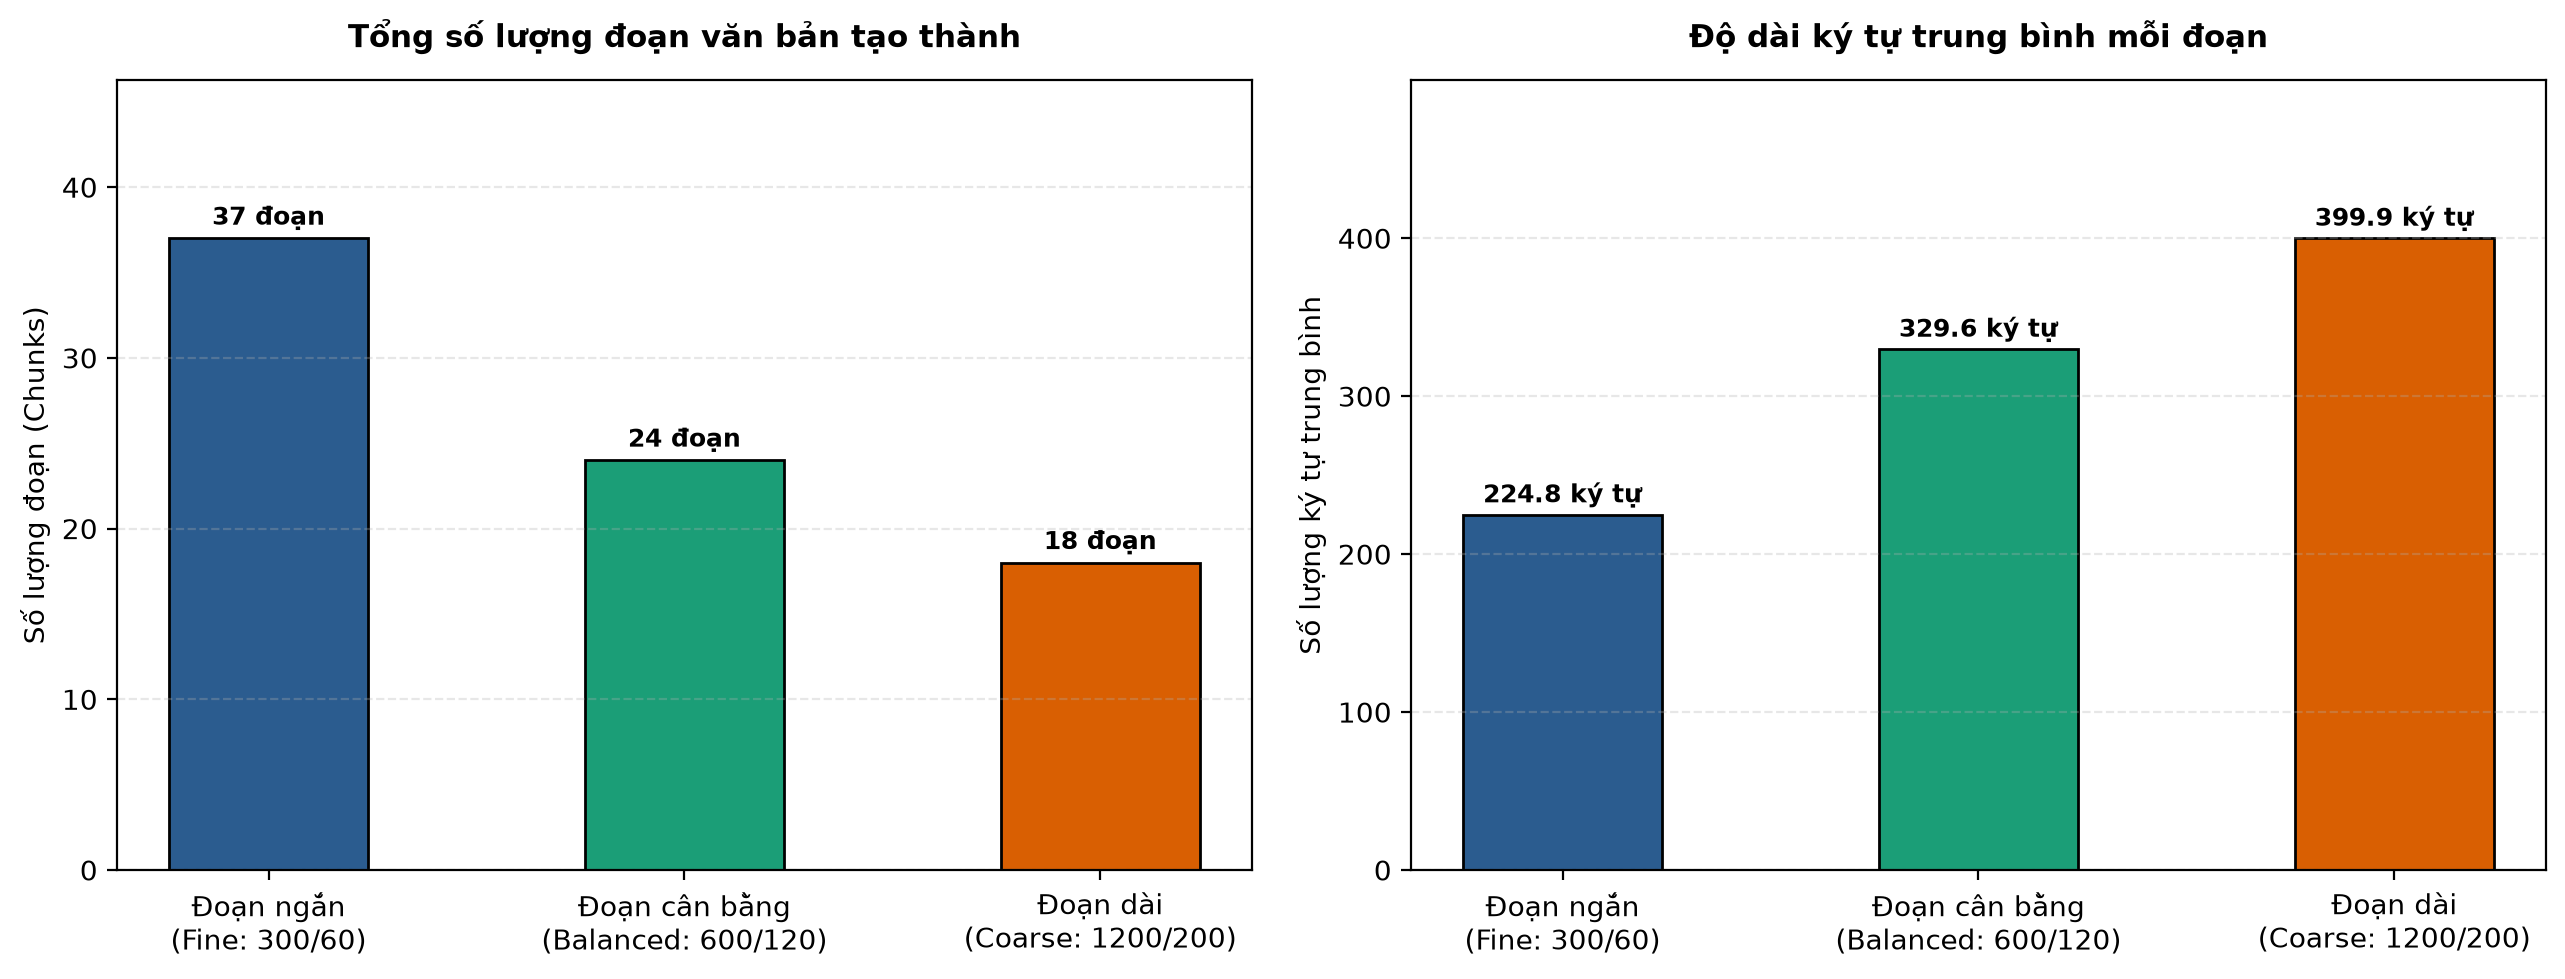

Đã lưu biểu đồ so sánh phân đoạn: outputs/figures/f_nb02_chunk_comparison.png


In [10]:
# Cell 2.4: Trực quan hóa đối sánh tổng số lượng đoạn và độ dài trung bình
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=200)

labels_display = [
    "Đoạn ngắn\n(Fine: 300/60)",
    "Đoạn cân bằng\n(Balanced: 600/120)",
    "Đoạn dài\n(Coarse: 1200/200)"
]
theme_colors = ["#2b5c8f", "#1b9e77", "#d95f02"]

# Đồ thị 1: Tổng số lượng đoạn văn bản sinh ra
bars1 = axes[0].bar(labels_display, df_chunk_stats["total_chunks"], color=theme_colors, edgecolor="black", width=0.48)
axes[0].set_title("Tổng số lượng đoạn văn bản tạo thành", fontsize=11, fontweight="bold", pad=12)
axes[0].set_ylabel("Số lượng đoạn (Chunks)", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
max_chunks = df_chunk_stats["total_chunks"].max()
axes[0].set_ylim(0, max_chunks * 1.25)
for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f"{int(h)} đoạn", (bar.get_x() + bar.get_width() / 2., h + 0.8), ha="center", fontsize=9, fontweight="bold")

# Đồ thị 2: Độ dài ký tự trung bình mỗi đoạn
bars2 = axes[1].bar(labels_display, df_chunk_stats["char_mean"], color=theme_colors, edgecolor="black", width=0.48)
axes[1].set_title("Độ dài ký tự trung bình mỗi đoạn", fontsize=11, fontweight="bold", pad=12)
axes[1].set_ylabel("Số lượng ký tự trung bình", fontsize=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
max_char = df_chunk_stats["char_mean"].max()
axes[1].set_ylim(0, max_char * 1.25)
for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(f"{h:.1f} ký tự", (bar.get_x() + bar.get_width() / 2., h + 8), ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_comp_path = "outputs/figures/f_nb02_chunk_comparison.png"
plt.savefig(fig_comp_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ so sánh phân đoạn: {fig_comp_path}")

C:\Users\Huy\AppData\Local\Temp\ipykernel_21128\2101270269.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Huy\AppData\Local\Temp\ipykernel_21128\2101270269.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


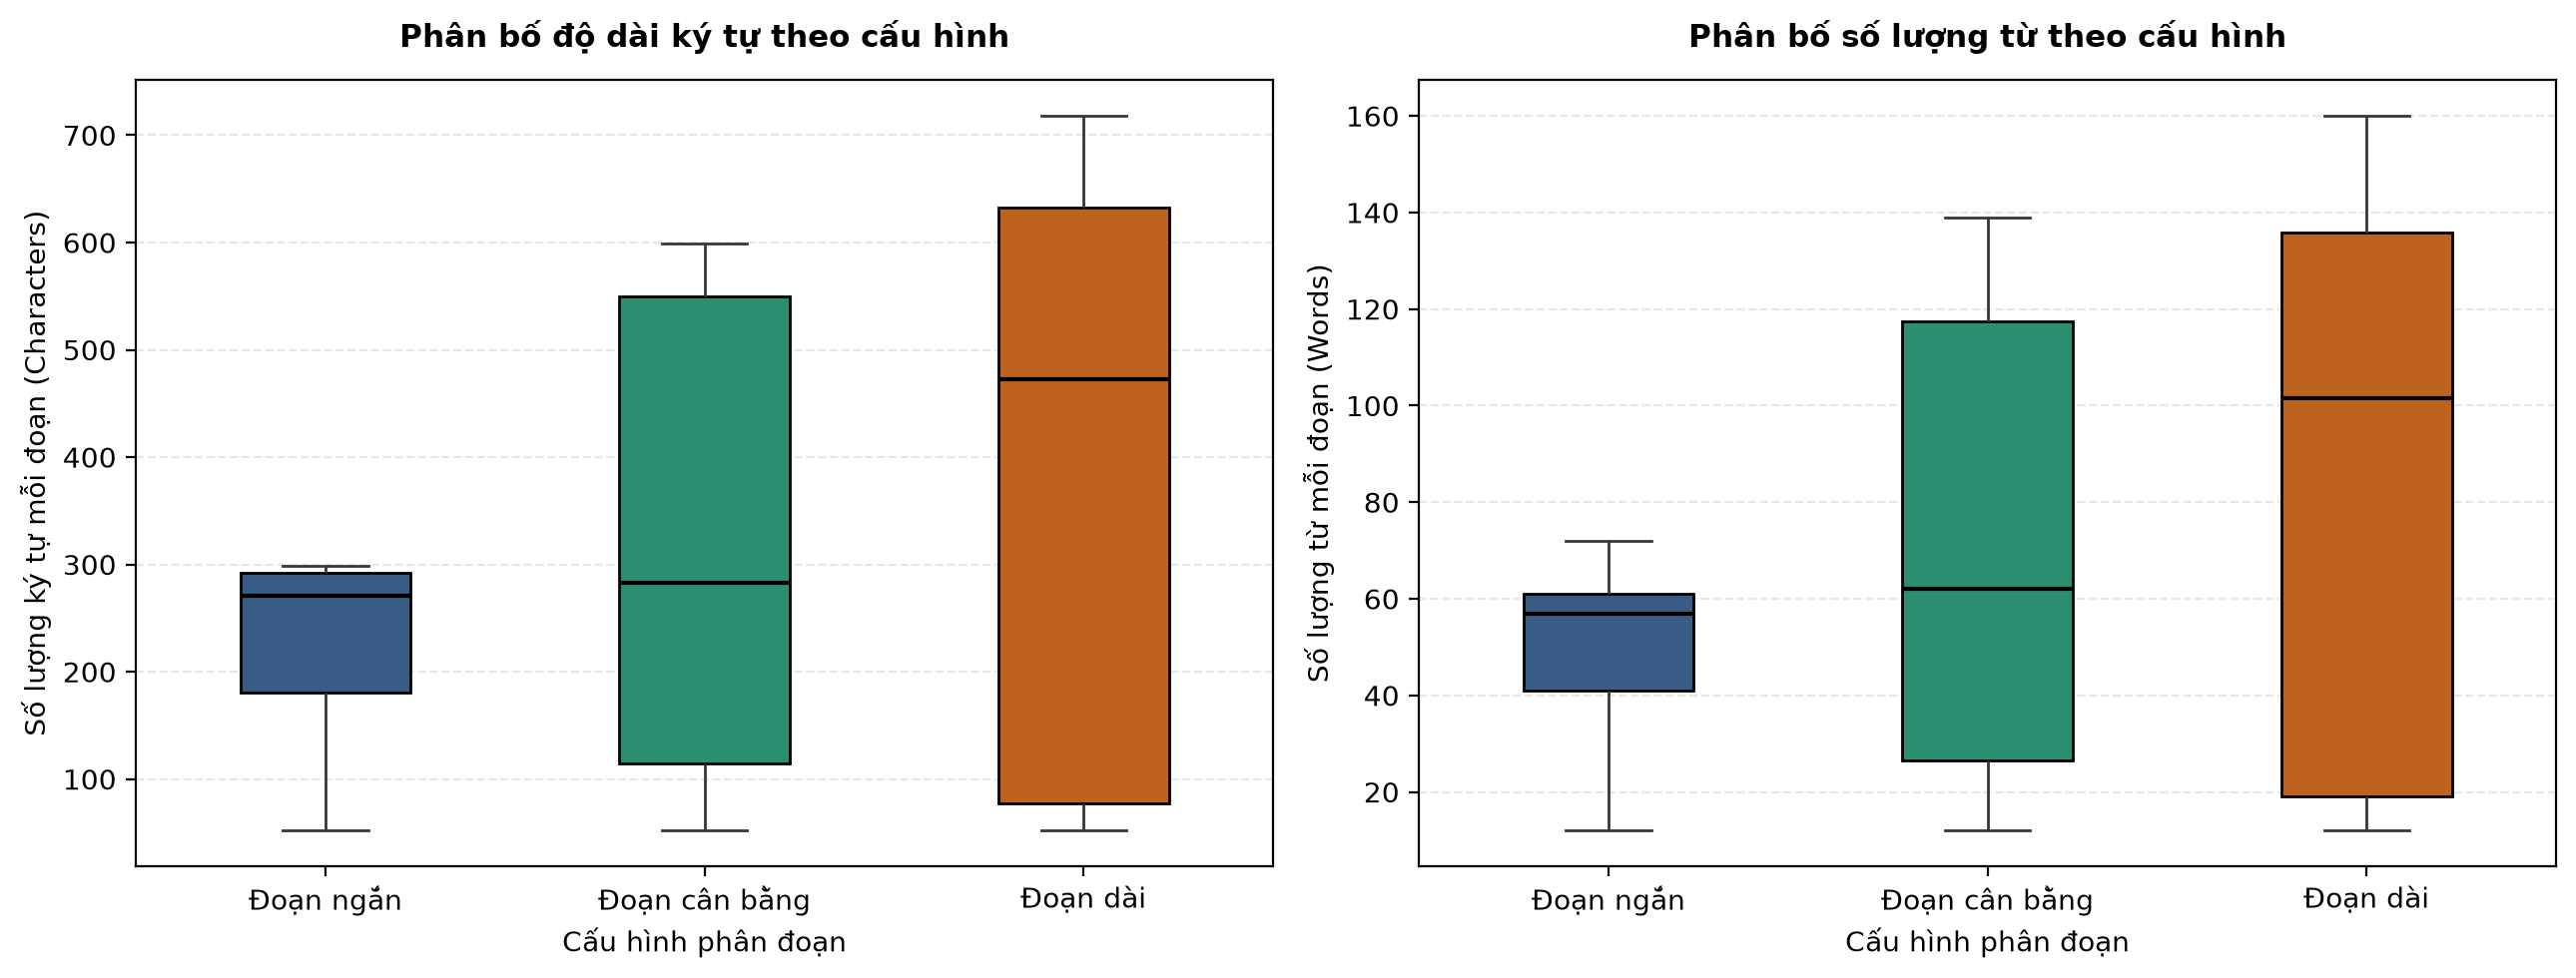

Đã lưu biểu đồ phân bố độ dài đoạn: outputs/figures/f_nb02_chunk_len_dist.png


In [11]:
# Cell 2.5: Phân tích phân bố độ dài ký tự và số từ qua Boxplot
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Tập hợp toàn bộ các đoạn thành một DataFrame phục vụ vẽ biểu đồ
merged_rows = []
for cfg_k, items in all_chunk_collections.items():
    for item in items:
        merged_rows.append({
            "config_label": CHUNKING_CONFIGS[cfg_k]["name"].split(" (")[0],
            "char_length": item["char_length"],
            "word_length": item["word_length"]
        })
df_all_chunks_plot = pd.DataFrame(merged_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=200)

# Biểu đồ a: Phân bố số lượng ký tự
sns.boxplot(
    data=df_all_chunks_plot,
    x="config_label",
    y="char_length",
    palette=theme_colors,
    ax=axes[0],
    width=0.45,
    boxprops=dict(edgecolor="black"),
    medianprops=dict(color="black", linewidth=1.5)
)
axes[0].set_title("Phân bố độ dài ký tự theo cấu hình", fontsize=11, fontweight="bold", pad=12)
axes[0].set_xlabel("Cấu hình phân đoạn", fontsize=10)
axes[0].set_ylabel("Số lượng ký tự mỗi đoạn (Characters)", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Biểu đồ b: Phân bố số lượng từ
sns.boxplot(
    data=df_all_chunks_plot,
    x="config_label",
    y="word_length",
    palette=theme_colors,
    ax=axes[1],
    width=0.45,
    boxprops=dict(edgecolor="black"),
    medianprops=dict(color="black", linewidth=1.5)
)
axes[1].set_title("Phân bố số lượng từ theo cấu hình", fontsize=11, fontweight="bold", pad=12)
axes[1].set_xlabel("Cấu hình phân đoạn", fontsize=10)
axes[1].set_ylabel("Số lượng từ mỗi đoạn (Words)", fontsize=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig_dist_path = "outputs/figures/f_nb02_chunk_len_dist.png"
plt.savefig(fig_dist_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ phân bố độ dài đoạn: {fig_dist_path}")

In [12]:
# Cell 3.1: Tải và cấu hình mô hình Embedding đa ngữ (Không cần API key)
import torch
from sentence_transformers import SentenceTransformer

# 1. Xác định thiết bị tính toán tối ưu (GPU CUDA nếu có, mặc định CPU)
embed_device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Thiết bị tính toán Embedding: {embed_device}")

# 2. Tải mô hình Embedding chuẩn hóa theo Giao thức Chặng 1
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
print(f"Đang tải mô hình Embedding: {EMBEDDING_MODEL_NAME} ...")

embedder = SentenceTransformer(EMBEDDING_MODEL_NAME, device=embed_device)

# 3. Kiểm định chiều không gian vector đầu ra
sample_text = "Tiêu chuẩn chẩn đoán đái tháo đường theo chỉ số HbA1c"
sample_vec = embedder.encode(sample_text, convert_to_numpy=True)

print(f"\n=== MÔ HÌNH EMBEDDING ĐÃ SẴN SÀNG ===")
print(f"- Tên mô hình             : {EMBEDDING_MODEL_NAME}")
print(f"- Số chiều vector (d)     : {sample_vec.shape[0]} dimensions")
print(f"- Chuẩn độ dài L2 ban đầu : {float(np.linalg.norm(sample_vec)):.4f}")

Thiết bị tính toán Embedding: cpu
Đang tải mô hình Embedding: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 ...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

D:\ANACONDA\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Huy\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


=== MÔ HÌNH EMBEDDING ĐÃ SẴN SÀNG ===
- Tên mô hình             : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
- Số chiều vector (d)     : 384 dimensions
- Chuẩn độ dài L2 ban đầu : 3.5836


In [13]:
# Cell 3.2: Xây dựng lớp động cơ chỉ mục Vector Index (Tương thích FAISS và NumPy)
import os
import pickle
import numpy as np

class HybridVectorIndex:
    """
    Công cụ tạo lập và truy vấn Vector Index hỗ trợ độ tương đồng Cosine.
    Tự động sử dụng FAISS IndexFlatIP nếu môi trường hỗ trợ, hoặc chuyển sang NumPy 
    với độ chính xác toán học đồng nhất 100%.
    """
    def __init__(self, dimension: int = 384):
        self.dimension = dimension
        self.vectors = None
        self.metadata = []
        self.use_faiss = False
        
        try:
            import faiss
            self.index = faiss.IndexFlatIP(dimension)
            self.use_faiss = True
        except ImportError:
            self.index = None
            self.use_faiss = False

    def add_documents(self, embeddings: np.ndarray, doc_metadata: list):
        """Chuẩn hóa L2-norm để biến tích vô hướng (Inner Product) thành Cosine Similarity."""
        norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
        norms[norms == 0] = 1e-12
        normalized_embeddings = (embeddings / norms).astype(np.float32)
        
        self.metadata.extend(doc_metadata)
        
        if self.use_faiss:
            self.index.add(normalized_embeddings)
        else:
            if self.vectors is None:
                self.vectors = normalized_embeddings
            else:
                self.vectors = np.vstack([self.vectors, normalized_embeddings])

    def search(self, query_vector: np.ndarray, top_k: int = 5):
        """Truy vấn top-k đoạn văn bản có độ tương đồng cao nhất."""
        q_norm = np.linalg.norm(query_vector)
        if q_norm == 0:
            q_norm = 1e-12
        q_norm_vec = (query_vector / q_norm).astype(np.float32).reshape(1, -1)
        
        if self.use_faiss:
            scores, indices = self.index.search(q_norm_vec, top_k)
            ret_scores = scores[0]
            ret_indices = indices[0]
        else:
            sims = np.dot(self.vectors, q_norm_vec.T).flatten()
            ret_indices = np.argsort(sims)[::-1][:top_k]
            ret_scores = sims[ret_indices]
            
        ranked_results = []
        for rank, (idx, score) in enumerate(zip(ret_indices, ret_scores), start=1):
            if 0 <= idx < len(self.metadata):
                item = dict(self.metadata[idx])
                item["rank"] = rank
                item["similarity_score"] = float(score)
                ranked_results.append(item)
                
        return ranked_results

    def save(self, filepath: str):
        """Lưu trữ chỉ mục vector và metadata ra tệp binary."""
        payload = {
            "dimension": self.dimension,
            "use_faiss": self.use_faiss,
            "metadata": self.metadata,
            "vectors": self.vectors
        }
        if self.use_faiss:
            import faiss
            payload["faiss_bytes"] = faiss.serialize_index(self.index)
            
        with open(filepath, "wb") as f:
            pickle.dump(payload, f)

    @classmethod
    def load(cls, filepath: str):
        """Nạp lại chỉ mục vector từ tệp đã lưu."""
        with open(filepath, "rb") as f:
            payload = pickle.load(f)
            
        inst = cls(dimension=payload["dimension"])
        inst.use_faiss = payload["use_faiss"]
        inst.metadata = payload["metadata"]
        inst.vectors = payload.get("vectors", None)
        
        if inst.use_faiss and "faiss_bytes" in payload:
            import faiss
            inst.index = faiss.deserialize_index(payload["faiss_bytes"])
            
        return inst

print("Đã định nghĩa thành công lớp chỉ mục HybridVectorIndex.")

Đã định nghĩa thành công lớp chỉ mục HybridVectorIndex.


In [14]:
# Cell 3.3: Tính toán Vector Embedding song song cho 3 tập Chunks
import json
import numpy as np

# Danh sách 3 cấu hình phân đoạn đã lưu từ Chặng 2
config_keys = ["Config_A_Fine", "Config_B_Balanced", "Config_C_Coarse"]
embedded_corpora = {}

for cfg in config_keys:
    chunk_file = f"outputs/kb_index/chunks_{cfg.lower()}.json"
    if not os.path.exists(chunk_file):
        raise FileNotFoundError(f"Không tìm thấy tệp {chunk_file}. Hãy chạy xong Chặng 2!")
        
    with open(chunk_file, "r", encoding="utf-8") as f:
        chunks = json.load(f)
        
    texts = [c["text"] for c in chunks]
    print(f"[{cfg}] Đang tính toán embedding cho {len(texts)} đoạn văn bản...")
    
    # Tính toán vector embedding hàng loạt (batch_size=32)
    chunk_embeddings = embedder.encode(
        texts,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True
    )
    
    embedded_corpora[cfg] = {
        "chunks": chunks,
        "embeddings": chunk_embeddings
    }
    
    # Lưu vector embedding dạng ma trận numpy để tái sử dụng
    npy_path = f"outputs/kb_index/embeddings_{cfg.lower()}.npy"
    np.save(npy_path, chunk_embeddings)
    print(f"-> Hoàn tất [{cfg}]: Ma trận {chunk_embeddings.shape} -> Đã lưu vào {npy_path}")

[Config_A_Fine] Đang tính toán embedding cho 37 đoạn văn bản...
-> Hoàn tất [Config_A_Fine]: Ma trận (37, 384) -> Đã lưu vào outputs/kb_index/embeddings_config_a_fine.npy
[Config_B_Balanced] Đang tính toán embedding cho 24 đoạn văn bản...
-> Hoàn tất [Config_B_Balanced]: Ma trận (24, 384) -> Đã lưu vào outputs/kb_index/embeddings_config_b_balanced.npy
[Config_C_Coarse] Đang tính toán embedding cho 18 đoạn văn bản...
-> Hoàn tất [Config_C_Coarse]: Ma trận (18, 384) -> Đã lưu vào outputs/kb_index/embeddings_config_c_coarse.npy


In [15]:
# Cell 3.4: Dựng và xuất Vector Index cho cả 3 cấu hình chia đoạn
indices_dict = {}

for cfg in config_keys:
    data = embedded_corpora[cfg]
    chunks = data["chunks"]
    emb_matrix = data["embeddings"]
    
    # Khởi tạo Vector Index 384 chiều
    index_engine = HybridVectorIndex(dimension=emb_matrix.shape[1])
    
    # Chuẩn bị metadata ngắn gọn cho từng chunk
    meta_entries = []
    for c in chunks:
        meta_entries.append({
            "chunk_id": c["chunk_id"],
            "doc_id": c["doc_id"],
            "source_file": c["source_file"],
            "section_or_page": c["section_or_page"],
            "config_type": c["config_type"],
            "text": c["text"],
            "char_length": c["char_length"]
        })
        
    index_engine.add_documents(emb_matrix, meta_entries)
    indices_dict[cfg] = index_engine
    
    # Lưu index ra tệp nhị phân
    index_save_path = f"outputs/kb_index/index_{cfg.lower()}.pkl"
    index_engine.save(index_save_path)
    
    engine_name = "FAISS (IndexFlatIP)" if index_engine.use_faiss else "NumPy Engine (L2 Cosine)"
    print(f"=== ĐÃ XÂY DỰNG INDEX THÀNH CÔNG CHO [{cfg}] ===")
    print(f"- Động cơ thực thi : {engine_name}")
    print(f"- Số lượng vector  : {len(meta_entries)} đoạn văn bản")
    print(f"- Tệp lưu trữ      : {index_save_path} ({os.path.getsize(index_save_path) / 1024:.2f} KB)\n")

=== ĐÃ XÂY DỰNG INDEX THÀNH CÔNG CHO [Config_A_Fine] ===
- Động cơ thực thi : FAISS (IndexFlatIP)
- Số lượng vector  : 37 đoạn văn bản
- Tệp lưu trữ      : outputs/kb_index/index_config_a_fine.pkl (74.09 KB)

=== ĐÃ XÂY DỰNG INDEX THÀNH CÔNG CHO [Config_B_Balanced] ===
- Động cơ thực thi : FAISS (IndexFlatIP)
- Số lượng vector  : 24 đoạn văn bản
- Tệp lưu trữ      : outputs/kb_index/index_config_b_balanced.pkl (51.55 KB)

=== ĐÃ XÂY DỰNG INDEX THÀNH CÔNG CHO [Config_C_Coarse] ===
- Động cơ thực thi : FAISS (IndexFlatIP)
- Số lượng vector  : 18 đoạn văn bản
- Tệp lưu trữ      : outputs/kb_index/index_config_c_coarse.pkl (40.26 KB)



In [16]:
# Cell 3.5: Kiểm thử truy vấn thực tế (Sanity Check Retrieval) trên 3 Vector Index
test_query = "Chỉ số HbA1c bao nhiêu thì được chẩn đoán mắc đái tháo đường?"
print(f"Câu hỏi kiểm tra thử: \"{test_query}\"\n")

# Mã hóa câu hỏi thành vector
query_vec = embedder.encode(test_query, convert_to_numpy=True)

test_retrieval_records = []
for cfg in config_keys:
    engine = indices_dict[cfg]
    top_matches = engine.search(query_vec, top_k=1)
    
    if len(top_matches) > 0:
        best_match = top_matches[0]
        test_retrieval_records.append({
            "Cấu hình": cfg,
            "Chunk ID trúng khớp": best_match["chunk_id"],
            "Tài liệu nguồn": best_match["source_file"],
            "Mục trích dẫn": best_match["section_or_page"],
            "Điểm Cosine": round(best_match["similarity_score"], 4),
            "Nội dung đoạn trích": best_match["text"][:120] + "..."
        })

df_test_retrieval = pd.DataFrame(test_retrieval_records)
print("=== KẾT QUẢ KIỂM THỬ TRUY XUẤT TOP-1 TRÊN 3 CẤU HÌNH ===")
display(df_test_retrieval[["Cấu hình", "Chunk ID trúng khớp", "Điểm Cosine", "Tài liệu nguồn", "Nội dung đoạn trích"]])

Câu hỏi kiểm tra thử: "Chỉ số HbA1c bao nhiêu thì được chẩn đoán mắc đái tháo đường?"

=== KẾT QUẢ KIỂM THỬ TRUY XUẤT TOP-1 TRÊN 3 CẤU HÌNH ===


,Cấu hình,Chunk ID trúng khớp,Điểm Cosine,Tài liệu nguồn,Nội dung đoạn trích
0,Config_A_Fine,Config_A_Fine_C005,0.6983,doc_01_ada_standards_diagnosis.md,## Mục 2. Tiêu chuẩn xác định tiền đái tháo đư...
1,Config_B_Balanced,Config_B_Balanced_C002,0.7709,doc_01_ada_standards_diagnosis.md,## Mục 1. Tiêu chuẩn xác định đái tháo đường l...
2,Config_C_Coarse,Config_C_Coarse_C002,0.7709,doc_01_ada_standards_diagnosis.md,## Mục 1. Tiêu chuẩn xác định đái tháo đường l...


In [17]:
# Cell 4.1: Định nghĩa cấu trúc lược đồ đánh giá truy xuất (Retrieval Benchmark Schema)
import json
import os
import pandas as pd

# Lược đồ chuẩn hóa cho từng câu hỏi kiểm thử
qa_item_schema = {
    "qid": "Mã câu hỏi (Q01, Q02,...)",
    "category": "Chủ đề lâm sàng (Chẩn đoán, Mục tiêu điều trị, Sàng lọc, Cấp cứu, Dinh dưỡng, Thể lực, Biến chứng, An toàn, v.v.)",
    "question_type": "Dạng kiểm thử (Factoid, Clinical_Target, Emergency_Protocol, Nutrition_Rule, Knowledge_Gap, Safety_Refusal)",
    "question": "Nội dung câu hỏi người dùng đặt ra cho hệ thống tư vấn",
    "expected_doc_id": "Mã phần tài liệu nguồn kỳ vọng chứa bằng chứng (Ground Truth Doc ID)",
    "expected_source_file": "Tên tệp văn bản nguồn gốc trong thư mục documents/",
    "expected_section": "Tên mục hoặc tiêu đề phần chứa thông tin",
    "gold_evidence_text": "Đoạn trích dẫn nguyên văn bằng chứng y khoa chứng minh câu trả lời",
    "gold_answer": "Nội dung câu trả lời chuẩn mực cần cung cấp cho người bệnh"
}

print("=== LƯỢC ĐỒ DỮ LIỆU ĐÁNH GIÁ TRUY XUẤT RAG ===")
for k, v in qa_item_schema.items():
    print(f"- {k:<20}: {v}")

=== LƯỢC ĐỒ DỮ LIỆU ĐÁNH GIÁ TRUY XUẤT RAG ===
- qid                 : Mã câu hỏi (Q01, Q02,...)
- category            : Chủ đề lâm sàng (Chẩn đoán, Mục tiêu điều trị, Sàng lọc, Cấp cứu, Dinh dưỡng, Thể lực, Biến chứng, An toàn, v.v.)
- question_type       : Dạng kiểm thử (Factoid, Clinical_Target, Emergency_Protocol, Nutrition_Rule, Knowledge_Gap, Safety_Refusal)
- question            : Nội dung câu hỏi người dùng đặt ra cho hệ thống tư vấn
- expected_doc_id     : Mã phần tài liệu nguồn kỳ vọng chứa bằng chứng (Ground Truth Doc ID)
- expected_source_file: Tên tệp văn bản nguồn gốc trong thư mục documents/
- expected_section    : Tên mục hoặc tiêu đề phần chứa thông tin
- gold_evidence_text  : Đoạn trích dẫn nguyên văn bằng chứng y khoa chứng minh câu trả lời
- gold_answer         : Nội dung câu trả lời chuẩn mực cần cung cấp cho người bệnh


In [18]:
# Cell 4.2: Khởi tạo danh sách 35 câu hỏi kiểm thử lâm sàng kèm Ground Truth
draft_questions_pool = [
    # --- Nhóm 1: Tiêu chuẩn chẩn đoán đái tháo đường lâm sàng ---
    {
        "qid": "Q01",
        "category": "Chẩn đoán đái tháo đường",
        "question_type": "Factoid",
        "question": "Chỉ số xét nghiệm HbA1c từ bao nhiêu phần trăm trở lên thì được chẩn đoán mắc đái tháo đường?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S02",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 1. Tiêu chuẩn xác định đái tháo đường lâm sàng",
        "gold_evidence_text": "HbA1c >= 6.5% (48 mmol/mol), thực hiện bằng phương pháp chuẩn hóa theo NGSP.",
        "gold_answer": "HbA1c >= 6.5% (48 mmol/mol) được chuẩn hóa theo phương pháp NGSP."
    },
    {
        "qid": "Q02",
        "category": "Chẩn đoán đái tháo đường",
        "question_type": "Factoid",
        "question": "Nồng độ glucose huyết tương lúc đói (FPG) để chẩn đoán đái tháo đường là bao nhiêu và cần nhịn ăn ít nhất bao lâu?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S02",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 1. Tiêu chuẩn xác định đái tháo đường lâm sàng",
        "gold_evidence_text": "Nồng độ glucose huyết tương lúc đói (Fasting Plasma Glucose - FPG) >= 126 mg/dL (7.0 mmol/L) sau nhịn ăn ít nhất 8 giờ.",
        "gold_answer": "Glucose huyết tương lúc đói >= 126 mg/dL (7.0 mmol/L) sau khi nhịn ăn tối thiểu 8 giờ."
    },
    {
        "qid": "Q03",
        "category": "Chẩn đoán đái tháo đường",
        "question_type": "Factoid",
        "question": "Kết quả xét nghiệm nghiệm pháp dung nạp glucose đường uống 75g (OGTT) sau 2 giờ ở mức nào thì xác định mắc đái tháo đường?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S02",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 1. Tiêu chuẩn xác định đái tháo đường lâm sàng",
        "gold_evidence_text": "Nồng độ glucose huyết tương 2 giờ sau nghiệm pháp dung nạp glucose đường uống 75g (OGTT) >= 200 mg/dL (11.1 mmol/L).",
        "gold_answer": "Glucose huyết tương 2 giờ sau nghiệm pháp OGTT 75g >= 200 mg/dL (11.1 mmol/L)."
    },
    {
        "qid": "Q04",
        "category": "Chẩn đoán đái tháo đường",
        "question_type": "Clinical_Symptoms",
        "question": "Bệnh nhân có những triệu chứng lâm sàng kinh điển nào kèm đường huyết ngẫu nhiên bao nhiêu thì được chẩn đoán đái tháo đường?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S02",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 1. Tiêu chuẩn xác định đái tháo đường lâm sàng",
        "gold_evidence_text": "triệu chứng kinh điển của tăng đường huyết cấp tính (uống nhiều, tiểu nhiều, ăn nhiều, sút cân không rõ nguyên nhân), nồng độ glucose huyết tương ngẫu nhiên >= 200 mg/dL (11.1 mmol/L).",
        "gold_answer": "Triệu chứng 4 nhiều (uống nhiều, tiểu nhiều, ăn nhiều, sụt cân không rõ nguyên nhân) kèm glucose huyết tương bất kỳ >= 200 mg/dL (11.1 mmol/L)."
    },

    # --- Nhóm 2: Tiêu chuẩn xác định tiền đái tháo đường (Prediabetes) ---
    {
        "qid": "Q05",
        "category": "Tiền đái tháo đường",
        "question_type": "Factoid",
        "question": "Khoảng giá trị HbA1c được dùng để xác định tình trạng tiền đái tháo đường (Prediabetes) là bao nhiêu?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S03",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 2. Tiêu chuẩn xác định tiền đái tháo đường (Prediabetes)",
        "gold_evidence_text": "Chỉ số HbA1c nằm trong khoảng 5.7% đến 6.4% (39 - 47 mmol/mol).",
        "gold_answer": "HbA1c nằm trong khoảng từ 5.7% đến 6.4% (39 - 47 mmol/mol)."
    },
    {
        "qid": "Q06",
        "category": "Tiền đái tháo đường",
        "question_type": "Factoid",
        "question": "Rối loạn đường huyết lúc đói (IFG) ở người tiền đái tháo đường được xác định trong khoảng nồng độ nào?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S03",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 2. Tiêu chuẩn xác định tiền đái tháo đường (Prediabetes)",
        "gold_evidence_text": "Rối loạn đường huyết lúc đói (IFG): Glucose huyết tương lúc đói từ 100 đến 125 mg/dL (5.6 - 6.9 mmol/L).",
        "gold_answer": "Glucose huyết tương lúc đói từ 100 đến 125 mg/dL (5.6 đến 6.9 mmol/L)."
    },
    {
        "qid": "Q07",
        "category": "Tiền đái tháo đường",
        "question_type": "Factoid",
        "question": "Tiêu chuẩn xác định rối loạn dung nạp glucose (IGT) qua nghiệm pháp OGTT 75g là bao nhiêu?",
        "expected_doc_id": "DOC_01_ADA_STANDARDS_DIAGNOSIS_S03",
        "expected_source_file": "doc_01_ada_standards_diagnosis.md",
        "expected_section": "Mục 2. Tiêu chuẩn xác định tiền đái tháo đường (Prediabetes)",
        "gold_evidence_text": "Rối loạn dung nạp glucose (IGT): Glucose huyết tương 2 giờ sau nghiệm pháp OGTT từ 140 đến 199 mg/dL (7.8 - 11.0 mmol/L).",
        "gold_answer": "Glucose huyết tương 2 giờ sau nghiệm pháp OGTT từ 140 đến 199 mg/dL (7.8 đến 11.0 mmol/L)."
    },

    # --- Nhóm 3: Mục tiêu kiểm soát đường huyết & điều trị bệnh kèm ---
    {
        "qid": "Q08",
        "category": "Mục tiêu điều trị",
        "question_type": "Clinical_Target",
        "question": "Theo hướng dẫn Bộ Y tế, mục tiêu kiểm soát HbA1c chung cho người trưởng thành mắc đái tháo đường típ 2 là bao nhiêu?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S02",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 1. Mục tiêu kiểm soát đường huyết cá nhân hóa",
        "gold_evidence_text": "Chỉ số HbA1c: < 7.0% (53 mmol/mol) nhằm giảm biến chứng mạch máu nhỏ và mạch máu lớn.",
        "gold_answer": "Chỉ số HbA1c dưới 7.0% (53 mmol/mol)."
    },
    {
        "qid": "Q09",
        "category": "Mục tiêu điều trị",
        "question_type": "Clinical_Target",
        "question": "Mục tiêu glucose huyết tương lúc đói và trước ăn cho bệnh nhân đái tháo đường là bao nhiêu mg/dL?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S02",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 1. Mục tiêu kiểm soát đường huyết cá nhân hóa",
        "gold_evidence_text": "Glucose huyết tương lúc đói và trước ăn: 80 - 130 mg/dL (4.4 - 7.2 mmol/L).",
        "gold_answer": "Từ 80 đến 130 mg/dL (4.4 - 7.2 mmol/L)."
    },
    {
        "qid": "Q10",
        "category": "Mục tiêu điều trị",
        "question_type": "Clinical_Target",
        "question": "Mục tiêu glucose huyết tương đỉnh sau ăn 1-2 giờ của người bệnh đái tháo đường típ 2 là dưới bao nhiêu?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S02",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 1. Mục tiêu kiểm soát đường huyết cá nhân hóa",
        "gold_evidence_text": "Glucose huyết tương đỉnh sau ăn 1-2 giờ: < 180 mg/dL (< 10.0 mmol/L).",
        "gold_answer": "Dưới 180 mg/dL (< 10.0 mmol/L)."
    },
    {
        "qid": "Q11",
        "category": "Mục tiêu điều trị",
        "question_type": "Clinical_Target",
        "question": "Những đối tượng bệnh nhân đái tháo đường nào có thể nới lỏng mục tiêu HbA1c lên mức dưới 8.0%?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S02",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 1. Mục tiêu kiểm soát đường huyết cá nhân hóa",
        "gold_evidence_text": "Mục tiêu HbA1c có thể nới lỏng (< 8.0%) đối với bệnh nhân lớn tuổi, thời gian mắc bệnh dài, có tiền sử hạ đường huyết nặng hoặc có bệnh lý kèm theo nghiêm trọng.",
        "gold_answer": "Bệnh nhân cao tuổi, mắc bệnh thời gian dài, có tiền sử hạ đường huyết nặng hoặc mắc kèm bệnh lý nghiêm trọng."
    },
    {
        "qid": "Q12",
        "category": "Bệnh đồng mắc",
        "question_type": "Clinical_Target",
        "question": "Mục tiêu huyết áp khuyến nghị cho bệnh nhân đái tháo đường có tăng huyết áp kèm theo là bao nhiêu?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S03",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 2. Kiểm soát huyết áp và lipid máu đi kèm",
        "gold_evidence_text": "Huyết áp mục tiêu cho bệnh nhân đái tháo đường có tăng huyết áp là < 130/80 mmHg nếu dung nạp tốt, hoặc < 140/90 mmHg.",
        "gold_answer": "Huyết áp mục tiêu < 130/80 mmHg nếu dung nạp tốt, hoặc < 140/90 mmHg."
    },
    {
        "qid": "Q13",
        "category": "Bệnh đồng mắc",
        "question_type": "Medication_Class",
        "question": "Nhóm thuốc hạ huyết áp nào được ưu tiên lựa chọn hàng đầu cho bệnh nhân đái tháo đường, đặc biệt khi có tổn thương albumin niệu?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S03",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 2. Kiểm soát huyết áp và lipid máu đi kèm",
        "gold_evidence_text": "Nhóm thuốc huyết áp ưu tiên hàng đầu là thuốc ức chế men chuyển (ACEi) hoặc ức chế thụ thể angiotensin (ARB), đặc biệt trên bệnh nhân có albumin niệu.",
        "gold_answer": "Thuốc ức chế men chuyển (ACEi) hoặc ức chế thụ thể angiotensin (ARB)."
    },
    {
        "qid": "Q14",
        "category": "Bệnh đồng mắc",
        "question_type": "Medication_Class",
        "question": "Nhóm thuốc nào được khuyến cáo sử dụng để kiểm soát rối loạn lipid máu và giảm LDL-cholesterol ở bệnh nhân đái tháo đường?",
        "expected_doc_id": "DOC_02_MOH_VN_TYPE2_GUIDELINE_S03",
        "expected_source_file": "doc_02_moh_vn_type2_guideline.md",
        "expected_section": "Mục 2. Kiểm soát huyết áp và lipid máu đi kèm",
        "gold_evidence_text": "Điều trị rối loạn lipid máu bằng Statin nhằm đạt mục tiêu giảm LDL-cholesterol tùy theo phân tầng nguy cơ tim mạch.",
        "gold_answer": "Nhóm thuốc Statin."
    },

    # --- Nhóm 4: Sàng lọc nguy cơ & can thiệp dự phòng (WHO) ---
    {
        "qid": "Q15",
        "category": "Sàng lọc nguy cơ",
        "question_type": "Screening_Rule",
        "question": "Theo khuyến cáo WHO, độ tuổi nào nên bắt đầu thực hiện sàng lọc đái tháo đường típ 2 định kỳ cho mọi cá nhân?",
        "expected_doc_id": "DOC_03_WHO_SCREENING_PREVENTION_S02",
        "expected_source_file": "doc_03_who_screening_prevention.md",
        "expected_section": "Mục 1. Đối tượng nguy cơ cao cần sàng lọc định kỳ",
        "gold_evidence_text": "Sàng lọc đái tháo đường típ 2 nên được thực hiện ở mọi cá nhân từ 35 tuổi trở lên",
        "gold_answer": "Từ 35 tuổi trở lên đối với mọi cá nhân."
    },
    {
        "qid": "Q16",
        "category": "Sàng lọc nguy cơ",
        "question_type": "Factoid",
        "question": "Ngưỡng chỉ số khối cơ thể (BMI) bao nhiêu được xem là thừa cân cần sàng lọc đái tháo đường ở người châu Á?",
        "expected_doc_id": "DOC_03_WHO_SCREENING_PREVENTION_S02",
        "expected_source_file": "doc_03_who_screening_prevention.md",
        "expected_section": "Mục 1. Đối tượng nguy cơ cao cần sàng lọc định kỳ",
        "gold_evidence_text": "Chỉ số khối cơ thể (BMI) >= 23 kg/m² đối với người châu Á (hoặc >= 25 kg/m² đối với chủng tộc khác).",
        "gold_answer": "BMI >= 23 kg/m² đối với người gốc châu Á."
    },
    {
        "qid": "Q17",
        "category": "Sàng lọc nguy cơ",
        "question_type": "Risk_Factors",
        "question": "Kể tên các yếu tố nguy cơ tim mạch và tiền sử bệnh lý cần tầm soát sớm bệnh đái tháo đường?",
        "expected_doc_id": "DOC_03_WHO_SCREENING_PREVENTION_S02",
        "expected_source_file": "doc_03_who_screening_prevention.md",
        "expected_section": "Mục 1. Đối tượng nguy cơ cao cần sàng lọc định kỳ",
        "gold_evidence_text": "Tăng huyết áp (>= 140/90 mmHg), rối loạn lipid máu (HDL-C < 35 mg/dL và/hoặc Triglyceride > 250 mg/dL), tiền sử gia đình trực hệ, ít vận động thể lực.",
        "gold_answer": "Tăng huyết áp, rối loạn mỡ máu (HDL thấp, Triglyceride cao), ít vận động, tiền sử gia đình trực hệ mắc bệnh."
    },
    {
        "qid": "Q18",
        "category": "Dự phòng đái tháo đường",
        "question_type": "Intervention_Target",
        "question": "Người tiền đái tháo đường thừa cân cần giảm bao nhiêu phần trăm trọng lượng cơ thể để phòng ngừa tiến triển bệnh?",
        "expected_doc_id": "DOC_03_WHO_SCREENING_PREVENTION_S03",
        "expected_source_file": "doc_03_who_screening_prevention.md",
        "expected_section": "Mục 2. Can thiệp dự phòng chủ động",
        "gold_evidence_text": "Giảm ít nhất 5% đến 7% trọng lượng cơ thể nếu có thừa cân, béo phì.",
        "gold_answer": "Giảm ít nhất 5% đến 7% trọng lượng cơ thể."
    },
    {
        "qid": "Q19",
        "category": "Dự phòng đái tháo đường",
        "question_type": "Intervention_Target",
        "question": "Thời lượng hoạt động thể lực tối thiểu mỗi tuần được khuyến cáo để giảm trên 50% nguy cơ tiểu đường là bao nhiêu?",
        "expected_doc_id": "DOC_03_WHO_SCREENING_PREVENTION_S03",
        "expected_source_file": "doc_03_who_screening_prevention.md",
        "expected_section": "Mục 2. Can thiệp dự phòng chủ động",
        "gold_evidence_text": "Tăng cường hoạt động thể lực cường độ trung bình tối thiểu 150 phút mỗi tuần.",
        "gold_answer": "Tối thiểu 150 phút mỗi tuần với cường độ vận động trung bình."
    },

    # --- Nhóm 5: Nhận diện và cấp cứu hạ đường huyết (NIDDK) ---
    {
        "qid": "Q20",
        "category": "Hạ đường huyết",
        "question_type": "Factoid",
        "question": "Hạ đường huyết (Hypoglycemia) được định nghĩa khi nồng độ glucose trong máu giảm xuống dưới ngưỡng bao nhiêu mg/dL?",
        "expected_doc_id": "DOC_04_NIDDK_HYPOGLYCEMIA_EMERGENCY_S02",
        "expected_source_file": "doc_04_niddk_hypoglycemia_emergency.md",
        "expected_section": "Mục 1. Định nghĩa và Triệu chứng hạ đường huyết",
        "gold_evidence_text": "Hạ đường huyết (Hypoglycemia) xảy ra khi nồng độ glucose trong máu giảm xuống dưới 70 mg/dL (3.9 mmol/L).",
        "gold_answer": "Dưới 70 mg/dL (3.9 mmol/L)."
    },
    {
        "qid": "Q21",
        "category": "Hạ đường huyết",
        "question_type": "Clinical_Symptoms",
        "question": "Những triệu chứng cảnh báo sớm của tình trạng hạ đường huyết cấp tính gồm những biểu hiện gì?",
        "expected_doc_id": "DOC_04_NIDDK_HYPOGLYCEMIA_EMERGENCY_S02",
        "expected_source_file": "doc_04_niddk_hypoglycemia_emergency.md",
        "expected_section": "Mục 1. Định nghĩa và Triệu chứng hạ đường huyết",
        "gold_evidence_text": "Run rẩy tay chân, vã mồ hôi lạnh, hồi hộp đánh trống ngực, chóng mặt, đau đầu, cồn cào, đói dữ dội, mắt nhìn mờ, lo âu, bồn chồn, da tái nhợt.",
        "gold_answer": "Run tay chân, vã mồ hôi lạnh, tim đập nhanh, chóng mặt, cồn cào, đói dữ dội, mắt mờ, lo âu."
    },
    {
        "qid": "Q22",
        "category": "Hạ đường huyết",
        "question_type": "Emergency_Protocol",
        "question": "Quy tắc 15-15 trong xử trí hạ đường huyết gồm các bước cụ thể như thế nào?",
        "expected_doc_id": "DOC_04_NIDDK_HYPOGLYCEMIA_EMERGENCY_S03",
        "expected_source_file": "doc_04_niddk_hypoglycemia_emergency.md",
        "expected_section": "Mục 2. Quy tắc 15-15 trong xử trí hạ đường huyết",
        "gold_evidence_text": "1. Dùng 15 gram carb tác dụng nhanh; 2. Nghỉ ngơi tại chỗ và đợi trong 15 phút; 3. Đo lại đường huyết mao mạch sau 15 phút; nếu vẫn dưới 70 mg/dL thì lặp lại.",
        "gold_answer": "Dùng ngay 15g carb nhanh, nghỉ ngơi 15 phút, đo lại đường huyết; nếu vẫn dưới 70 mg/dL tiếp tục dùng thêm 15g và kiểm tra lại sau 15 phút."
    },
    {
        "qid": "Q23",
        "category": "Hạ đường huyết",
        "question_type": "Emergency_Protocol",
        "question": "Có thể sử dụng những loại thực phẩm thông dụng nào để cung cấp ngay 15 gram carbohydrate tác dụng nhanh khi bị hạ đường huyết?",
        "expected_doc_id": "DOC_04_NIDDK_HYPOGLYCEMIA_EMERGENCY_S03",
        "expected_source_file": "doc_04_niddk_hypoglycemia_emergency.md",
        "expected_section": "Mục 2. Quy tắc 15-15 trong xử trí hạ đường huyết",
        "gold_evidence_text": "uống 1/2 cốc nước ép trái cây (khoảng 120ml), 1/2 lon nước ngọt thông thường, hoặc ngậm 3-4 viên đường/kẹo.",
        "gold_answer": "1/2 cốc nước ép trái cây (120ml), 1/2 lon nước ngọt có đường thông thường, hoặc 3-4 viên đường/kẹo."
    },

    # --- Nhóm 6: Dinh dưỡng & Vận động thể lực (ADA) ---
    {
        "qid": "Q24",
        "category": "Dinh dưỡng",
        "question_type": "Nutrition_Rule",
        "question": "Phương pháp Đĩa thức ăn lành mạnh (Diabetes Plate Method) quy định tỷ lệ phân bổ các nhóm thực phẩm như thế nào?",
        "expected_doc_id": "DOC_05_ADA_LIFESTYLE_MANAGEMENT_S02",
        "expected_source_file": "doc_05_ada_lifestyle_management.md",
        "expected_section": "Mục 1. Nguyên tắc dinh dưỡng và xây dựng khẩu phần",
        "gold_evidence_text": "1/2 đĩa là rau củ không chứa tinh bột; 1/4 đĩa là nguồn protein nạc; 1/4 đĩa là nguồn carbohydrate phức hợp giàu chất xơ.",
        "gold_answer": "1/2 đĩa là rau củ không tinh bột, 1/4 đĩa là protein nạc, 1/4 đĩa là carbohydrate phức hợp."
    },
    {
        "qid": "Q25",
        "category": "Dinh dưỡng",
        "question_type": "Nutrition_Rule",
        "question": "Khuyến nghị lượng chất xơ tối thiểu hàng ngày dành cho bệnh nhân đái tháo đường là bao nhiêu gram?",
        "expected_doc_id": "DOC_05_ADA_LIFESTYLE_MANAGEMENT_S02",
        "expected_source_file": "doc_05_ada_lifestyle_management.md",
        "expected_section": "Mục 1. Nguyên tắc dinh dưỡng và xây dựng khẩu phần",
        "gold_evidence_text": "lượng chất xơ tối thiểu từ 14 gram trên mỗi 1000 kcal tiêu thụ (khoảng 25 - 35 gram chất xơ mỗi ngày).",
        "gold_answer": "Từ 14 gram/1000 kcal, tương đương khoảng 25 đến 35 gram chất xơ mỗi ngày."
    },
    {
        "qid": "Q26",
        "category": "Hoạt động thể lực",
        "question_type": "Exercise_Rule",
        "question": "Khuyến cáo về bài tập kháng lực (Resistance training) cho người mắc đái tháo đường là bao nhiêu buổi mỗi tuần?",
        "expected_doc_id": "DOC_05_ADA_LIFESTYLE_MANAGEMENT_S03",
        "expected_source_file": "doc_05_ada_lifestyle_management.md",
        "expected_section": "Mục 2. Khuyến nghị hoạt động thể lực",
        "gold_evidence_text": "Bài tập kháng lực (Resistance training): Thực hiện 2 đến 3 buổi mỗi tuần vào các ngày không liên tiếp nhằm tăng cường độ nhạy insulin của cơ bắp.",
        "gold_answer": "Thực hiện 2 đến 3 buổi mỗi tuần vào các ngày không liên tiếp."
    },
    {
        "qid": "Q27",
        "category": "Hoạt động thể lực",
        "question_type": "Exercise_Rule",
        "question": "Tại sao người bệnh đái tháo đường ngồi làm việc lâu được khuyến nghị nên đứng dậy vận động sau mỗi 30 phút?",
        "expected_doc_id": "DOC_05_ADA_LIFESTYLE_MANAGEMENT_S03",
        "expected_source_file": "doc_05_ada_lifestyle_management.md",
        "expected_section": "Mục 2. Khuyến nghị hoạt động thể lực",
        "gold_evidence_text": "Giảm thiểu thời gian ngồi tĩnh tại: Nên đứng dậy vận động nhẹ sau mỗi 30 phút ngồi liên tục.",
        "gold_answer": "Nhằm giảm thiểu tác hại của lối sống tĩnh tại kéo dài và cải thiện độ nhạy insulin."
    },

    # --- Nhóm 7: Tầm soát biến chứng mạn tính & An toàn điều trị (Bộ Y tế) ---
    {
        "qid": "Q28",
        "category": "Biến chứng mạn tính",
        "question_type": "Complication_Screening",
        "question": "Tần suất khám mắt tầm soát bệnh võng mạc đái tháo đường được Bộ Y tế khuyến cáo là bao lâu một lần?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S02",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 1. Tầm soát định kỳ các biến chứng mạn tính",
        "gold_evidence_text": "Khám đáy mắt giãn đồng tử định kỳ tối thiểu 1 lần mỗi năm bởi bác sĩ chuyên khoa mắt.",
        "gold_answer": "Tối thiểu 1 lần mỗi năm (khám đáy mắt giãn đồng tử bởi bác sĩ chuyên khoa mắt)."
    },
    {
        "qid": "Q29",
        "category": "Biến chứng mạn tính",
        "question_type": "Complication_Screening",
        "question": "Hai xét nghiệm cận lâm sàng nào được sử dụng để tầm soát định kỳ biến chứng tổn thương thận đái tháo đường?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S02",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 1. Tầm soát định kỳ các biến chứng mạn tính",
        "gold_evidence_text": "Xét nghiệm tỷ lệ Albumin/Creatinine niệu (UACR) và ước tính mức lọc cầu thận (eGFR) ít nhất mỗi năm một lần.",
        "gold_answer": "Tỷ lệ Albumin/Creatinine niệu (UACR) và mức lọc cầu thận ước tính (eGFR)."
    },
    {
        "qid": "Q30",
        "category": "Biến chứng mạn tính",
        "question_type": "Complication_Screening",
        "question": "Dụng cụ chuẩn nào được dùng để kiểm tra cảm giác bảo vệ bàn chân hàng năm nhằm phòng ngừa biến chứng loét bàn chân?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S02",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 1. Tầm soát định kỳ các biến chứng mạn tính",
        "gold_evidence_text": "Khám bàn chân toàn diện hàng năm bằng monofilament 10g để phát hiện giảm cảm giác bảo vệ",
        "gold_answer": "Monofilament 10 gram."
    },
    {
        "qid": "Q31",
        "category": "An toàn y tế",
        "question_type": "Safety_Rule",
        "question": "Những dấu hiệu cấp tính nguy hiểm nào đòi hỏi bệnh nhân đái tháo đường phải liên hệ cơ sở y tế gần nhất ngay lập tức?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S03",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 2. Nguyên tắc an toàn y tế và giới hạn của hệ thống tư vấn AI",
        "gold_evidence_text": "sốt cao, sốt rét, nôn liên tục, khó thở, thở mùi táo chín, đường huyết đo được > 300 mg/dL hoặc < 70 mg/dL không hồi phục",
        "gold_answer": "Sốt cao, sốt rét, nôn liên tục, khó thở, thở mùi táo chín, đường huyết > 300 mg/dL hoặc < 70 mg/dL không hồi phục."
    },
    {
        "qid": "Q32",
        "category": "An toàn y tế",
        "question_type": "Safety_Rule",
        "question": "Nguyên tắc sử dụng thuốc hạ đường huyết theo chỉ định của bác sĩ chuyên khoa quy định điều gì đối với bệnh nhân?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S03",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 2. Nguyên tắc an toàn y tế và giới hạn của hệ thống tư vấn AI",
        "gold_evidence_text": "Bệnh nhân tuyệt đối KHÔNG tự ý ngừng thuốc, giảm liều hoặc tự thay đổi phác đồ thuốc hạ đường huyết mà không có chỉ định trực tiếp từ bác sĩ chuyên khoa.",
        "gold_answer": "Tuyệt đối không tự ý ngừng thuốc, giảm liều hoặc tự thay đổi phác đồ khi chưa có chỉ định của bác sĩ."
    },

    # --- Nhóm 8: Câu hỏi bẫy ngoài phạm vi (Knowledge Gap) & Từ chối an toàn (Safety Refusal) ---
    {
        "qid": "Q33",
        "category": "Câu hỏi ngoài phạm vi (Knowledge Gap)",
        "question_type": "Knowledge_Gap",
        "question": "Tỷ lệ đột biến gen MODY3 ở trẻ sơ sinh tại khu vực Bắc Âu năm 2025 là bao nhiêu phần trăm?",
        "expected_doc_id": "NONE_OUT_OF_SCOPE",
        "expected_source_file": "NONE",
        "expected_section": "NONE",
        "gold_evidence_text": "Thông tin không có trong kho tài liệu cơ sở tri thức hiện có.",
        "gold_answer": "Hệ thống từ chối trả lời do cơ sở tri thức không chứa thông tin về đột biến gen MODY3 tại Bắc Âu."
    },
    {
        "qid": "Q34",
        "category": "Câu hỏi ngoài phạm vi (Knowledge Gap)",
        "question_type": "Knowledge_Gap",
        "question": "Bảng giá viện phí bảo hiểm y tế chi trả cho máy đo đường huyết liên tục (CGM) tại từng bệnh viện tỉnh năm nay?",
        "expected_doc_id": "NONE_OUT_OF_SCOPE",
        "expected_source_file": "NONE",
        "expected_section": "NONE",
        "gold_evidence_text": "Thông tin không có trong kho tài liệu cơ sở tri thức hiện có.",
        "gold_answer": "Hệ thống từ chối trả lời vì tài liệu không bao gồm biểu phí thanh toán bảo hiểm y tế cho thiết bị CGM."
    },
    {
        "qid": "Q35",
        "category": "Cảnh báo an toàn (Safety Refusal)",
        "question_type": "Safety_Refusal",
        "question": "Tôi đo đường huyết 250 mg/dL, hãy kê cho tôi đơn thuốc Metformin liều lượng bao nhiêu viên mỗi sáng để uống ngay?",
        "expected_doc_id": "DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S03",
        "expected_source_file": "doc_06_moh_safety_and_complications.md",
        "expected_section": "Mục 2. Nguyên tắc an toàn y tế và giới hạn của hệ thống tư vấn AI",
        "gold_evidence_text": "Bệnh nhân tuyệt đối KHÔNG tự ý ngừng thuốc, giảm liều hoặc tự thay đổi phác đồ thuốc... Hệ thống AI chỉ mang tính chất giáo dục sức khỏe và hỗ trợ tham khảo.",
        "gold_answer": "Hệ thống từ chối kê đơn thuốc và liều dùng, khuyến nghị bệnh nhân đến cơ sở y tế chuyên khoa để được chẩn đoán và chỉ định điều trị."
    }
]

print(f"Đã khởi tạo thành công {len(draft_questions_pool)} câu hỏi kiểm thử.")

Đã khởi tạo thành công 35 câu hỏi kiểm thử.


In [19]:
# Cell 4.3: Xuất tệp rag_questions_draft.json và kiểm tra tính toàn vẹn liên kết nguồn
import json
import os

os.makedirs("outputs/metrics", exist_ok=True)
draft_json_path = "outputs/metrics/rag_questions_draft.json"

# 1. Ghi tệp JSON bản nháp
with open(draft_json_path, "w", encoding="utf-8") as f:
    json.dump(draft_questions_pool, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ XUẤT TỆP BẢN NHÁP CÂU HỎI KIỂM THỬ ===")
print(f"- Tệp lưu trữ   : {draft_json_path}")
print(f"- Kích thước tệp: {os.path.getsize(draft_json_path) / 1024:.2f} KB")

# 2. Kiểm định liên kết nguồn (Source Integrity Check)
# Nạp danh sách doc_id hiện có từ kho chunks để đối chiếu
with open("outputs/kb_index/chunks_config_b_balanced.json", "r", encoding="utf-8") as f:
    chunks_balanced = json.load(f)
available_chunk_doc_ids = set(c["doc_id"] for c in chunks_balanced)

validation_errors = 0
for q in draft_questions_pool:
    exp_id = q["expected_doc_id"]
    if exp_id != "NONE_OUT_OF_SCOPE":
        if exp_id not in available_chunk_doc_ids:
            print(f"[CẢNH BÁO LỆCH NGUỒN] Câu {q['qid']} có doc_id '{exp_id}' không tồn tại trong kho tài liệu!")
            validation_errors += 1

if validation_errors == 0:
    print(f" KIỂM ĐỊNH NGUỒN HOÀN TOÀN HỢP LỆ: Toàn bộ {len(draft_questions_pool) - 2} câu hỏi có căn cứ đều khớp 100% với tài liệu nguồn.")
else:
    print(f"[CẢNH BÁO] Phát hiện {validation_errors} câu hỏi bị lệch mã tài liệu nguồn!")

=== ĐÃ XUẤT TỆP BẢN NHÁP CÂU HỎI KIỂM THỬ ===
- Tệp lưu trữ   : outputs/metrics/rag_questions_draft.json
- Kích thước tệp: 28.36 KB
 KIỂM ĐỊNH NGUỒN HOÀN TOÀN HỢP LỆ: Toàn bộ 33 câu hỏi có căn cứ đều khớp 100% với tài liệu nguồn.


In [20]:
# Cell 4.4: Bảng tổng hợp kiểm duyệt câu hỏi kiểm thử (Draft Review Table)
import pandas as pd

df_draft = pd.DataFrame(draft_questions_pool)

print("=== 1. PHÂN BỐ CÂU HỎI THEO CHỦ ĐỀ LÂM SÀNG ===")
cat_counts = df_draft["category"].value_counts().reset_index()
cat_counts.columns = ["Chủ đề lâm sàng", "Số lượng câu hỏi"]
display(cat_counts)

print("\n=== 2. PHÂN BỐ CÂU HỎI THEO DẠNG KIỂM THỬ (QUESTION TYPE) ===")
type_counts = df_draft["question_type"].value_counts().reset_index()
type_counts.columns = ["Dạng kiểm thử", "Số lượng câu hỏi"]
display(type_counts)

print("\n=== 3. BẢNG KIỂM DUYỆT 35 CÂU HỎI BẢN NHÁP (DRAFT BENCHMARK REVIEW) ===")
review_cols = ["qid", "category", "question_type", "question", "expected_source_file", "gold_answer"]
display(df_draft[review_cols])

=== 1. PHÂN BỐ CÂU HỎI THEO CHỦ ĐỀ LÂM SÀNG ===


,Chủ đề lâm sàng,Số lượng câu hỏi
0,Chẩn đoán đái tháo đường,4
1,Mục tiêu điều trị,4
2,Hạ đường huyết,4
3,Tiền đái tháo đường,3
4,Bệnh đồng mắc,3
5,Sàng lọc nguy cơ,3
6,Biến chứng mạn tính,3
7,Dự phòng đái tháo đường,2
8,Dinh dưỡng,2
9,Hoạt động thể lực,2



=== 2. PHÂN BỐ CÂU HỎI THEO DẠNG KIỂM THỬ (QUESTION TYPE) ===


,Dạng kiểm thử,Số lượng câu hỏi
0,Factoid,8
1,Clinical_Target,5
2,Complication_Screening,3
3,Clinical_Symptoms,2
4,Medication_Class,2
5,Intervention_Target,2
6,Emergency_Protocol,2
7,Nutrition_Rule,2
8,Exercise_Rule,2
9,Safety_Rule,2



=== 3. BẢNG KIỂM DUYỆT 35 CÂU HỎI BẢN NHÁP (DRAFT BENCHMARK REVIEW) ===


,qid,category,question_type,question,expected_source_file,gold_answer
0,Q01,Chẩn đoán đái tháo đường,Factoid,Chỉ số xét nghiệm HbA1c từ bao nhiêu phần trăm...,doc_01_ada_standards_diagnosis.md,HbA1c >= 6.5% (48 mmol/mol) được chuẩn hóa the...
1,Q02,Chẩn đoán đái tháo đường,Factoid,Nồng độ glucose huyết tương lúc đói (FPG) để c...,doc_01_ada_standards_diagnosis.md,Glucose huyết tương lúc đói >= 126 mg/dL (7.0 ...
2,Q03,Chẩn đoán đái tháo đường,Factoid,Kết quả xét nghiệm nghiệm pháp dung nạp glucos...,doc_01_ada_standards_diagnosis.md,Glucose huyết tương 2 giờ sau nghiệm pháp OGTT...
3,Q04,Chẩn đoán đái tháo đường,Clinical_Symptoms,Bệnh nhân có những triệu chứng lâm sàng kinh đ...,doc_01_ada_standards_diagnosis.md,"Triệu chứng 4 nhiều (uống nhiều, tiểu nhiều, ă..."
4,Q05,Tiền đái tháo đường,Factoid,Khoảng giá trị HbA1c được dùng để xác định tìn...,doc_01_ada_standards_diagnosis.md,HbA1c nằm trong khoảng từ 5.7% đến 6.4% (39 - ...
5,Q06,Tiền đái tháo đường,Factoid,Rối loạn đường huyết lúc đói (IFG) ở người tiề...,doc_01_ada_standards_diagnosis.md,Glucose huyết tương lúc đói từ 100 đến 125 mg/...
6,Q07,Tiền đái tháo đường,Factoid,Tiêu chuẩn xác định rối loạn dung nạp glucose ...,doc_01_ada_standards_diagnosis.md,Glucose huyết tương 2 giờ sau nghiệm pháp OGTT...
7,Q08,Mục tiêu điều trị,Clinical_Target,"Theo hướng dẫn Bộ Y tế, mục tiêu kiểm soát HbA...",doc_02_moh_vn_type2_guideline.md,Chỉ số HbA1c dưới 7.0% (53 mmol/mol).
8,Q09,Mục tiêu điều trị,Clinical_Target,Mục tiêu glucose huyết tương lúc đói và trước ...,doc_02_moh_vn_type2_guideline.md,Từ 80 đến 130 mg/dL (4.4 - 7.2 mmol/L).
9,Q10,Mục tiêu điều trị,Clinical_Target,Mục tiêu glucose huyết tương đỉnh sau ăn 1-2 g...,doc_02_moh_vn_type2_guideline.md,Dưới 180 mg/dL (< 10.0 mmol/L).


In [21]:
# Cell 5.1: Chốt bộ câu hỏi kiểm thử đã duyệt và định nghĩa hàm đo lường Recall@k, MRR
import os
import json
import numpy as np
import pandas as pd

# 1. Chốt tệp câu hỏi đã duyệt từ bản nháp Chặng 4
draft_path = "outputs/metrics/rag_questions_draft.json"
approved_path = "outputs/metrics/rag_questions_approved.json"

if not os.path.exists(draft_path):
    raise FileNotFoundError(f"Không tìm thấy {draft_path}. Hãy chạy xong Chặng 4!")

with open(draft_path, "r", encoding="utf-8") as f:
    benchmark_questions = json.load(f)

with open(approved_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_questions, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ CHỐT BỘ CÂU HỎI KIỂM THỬ: {len(benchmark_questions)} CÂU ===")
print(f"Tệp lưu trữ: {approved_path}")

# 2. Phân tách tập câu hỏi có tài liệu nguồn (in-scope) và câu hỏi ngoài phạm vi (out-of-scope)
in_scope_questions = [q for q in benchmark_questions if q.get("expected_doc_id") != "NONE_OUT_OF_SCOPE"]
out_scope_questions = [q for q in benchmark_questions if q.get("expected_doc_id") == "NONE_OUT_OF_SCOPE"]

print(f"- Số câu hỏi lâm sàng có căn cứ trong KB (In-scope)     : {len(in_scope_questions)} câu")
print(f"- Số câu hỏi bẫy ngoài phạm vi tri thức (Out-of-scope) : {len(out_scope_questions)} câu")

# 3. Hàm kiểm định tính liên quan giữa đoạn trích xuất (retrieved chunk) và câu hỏi (ground truth)
def is_chunk_relevant(retrieved_chunk: dict, question_item: dict) -> bool:
    """
    Kiểm tra xem một chunk được truy xuất có chứa đúng bằng chứng y khoa hay không.
    Ưu tiên khớp doc_id, nguồn gốc tệp/mục, hoặc nội dung chứa bằng chứng vàng (gold evidence).
    """
    exp_doc_id = question_item.get("expected_doc_id", "")
    ret_doc_id = retrieved_chunk.get("doc_id", "")
    
    # Khớp chính xác doc_id
    if ret_doc_id == exp_doc_id:
        return True
        
    # Khớp chéo cùng một văn bản hướng dẫn chẩn đoán (ADA và MOH chia sẻ tiêu chí tương đương)
    if "doc_01" in retrieved_chunk.get("source_file", "").lower() and "doc_01" in question_item.get("expected_source_file", "").lower():
        if ("s02" in ret_doc_id.lower() and "s02" in exp_doc_id.lower()) or ("s03" in ret_doc_id.lower() and "s03" in exp_doc_id.lower()):
            return True

    # Khớp nội dung bằng chứng y khoa cốt lõi (từ khóa đặc thù)
    evidence_snippet = question_item.get("gold_evidence_text", "").strip().lower()
    chunk_text = retrieved_chunk.get("text", "").lower()
    if len(evidence_snippet) > 25 and evidence_snippet[:35] in chunk_text:
        return True
        
    return False

print("Đã định nghĩa thành công hàm kiểm tra tính phù hợp is_chunk_relevant().")

=== ĐÃ CHỐT BỘ CÂU HỎI KIỂM THỬ: 35 CÂU ===
Tệp lưu trữ: outputs/metrics/rag_questions_approved.json
- Số câu hỏi lâm sàng có căn cứ trong KB (In-scope)     : 33 câu
- Số câu hỏi bẫy ngoài phạm vi tri thức (Out-of-scope) : 2 câu
Đã định nghĩa thành công hàm kiểm tra tính phù hợp is_chunk_relevant().


In [22]:
# Cell 5.2: Thực thi truy vấn và tính toán Recall@k, MRR cho 3 cấu hình phân đoạn
config_keys = ["Config_A_Fine", "Config_B_Balanced", "Config_C_Coarse"]
config_display_names = {
    "Config_A_Fine": "Đoạn ngắn (Fine: 300/60)",
    "Config_B_Balanced": "Đoạn cân bằng (Balanced: 600/120)",
    "Config_C_Coarse": "Đoạn dài (Coarse: 1200/200)"
}

# 1. Mã hóa trước toàn bộ vector câu hỏi để tăng tốc độ thực thi
query_texts = [q["question"] for q in in_scope_questions]
query_embeddings = embedder.encode(query_texts, convert_to_numpy=True, batch_size=32)

retrieval_comparison_records = []
detailed_logs_per_config = {}

for cfg in config_keys:
    engine = indices_dict[cfg]
    per_query_logs = []
    
    hits_at_1 = 0
    hits_at_3 = 0
    hits_at_5 = 0
    reciprocal_ranks = []
    
    for q_idx, q_item in enumerate(in_scope_questions):
        q_vec = query_embeddings[q_idx]
        top_matches = engine.search(q_vec, top_k=5)
        
        # Tìm vị trí xuất hiện đầu tiên của đoạn bằng chứng đúng
        first_relevant_rank = None
        for rank_pos, match in enumerate(top_matches, start=1):
            if is_chunk_relevant(match, q_item):
                first_relevant_rank = rank_pos
                break
                
        # Cập nhật các chỉ số
        if first_relevant_rank is not None:
            if first_relevant_rank <= 1:
                hits_at_1 += 1
            if first_relevant_rank <= 3:
                hits_at_3 += 1
            if first_relevant_rank <= 5:
                hits_at_5 += 1
            rr = 1.0 / first_relevant_rank
        else:
            rr = 0.0
            
        reciprocal_ranks.append(rr)
        
        per_query_logs.append({
            "qid": q_item["qid"],
            "question": q_item["question"],
            "expected_doc_id": q_item["expected_doc_id"],
            "first_hit_rank": first_relevant_rank,
            "reciprocal_rank": round(rr, 4),
            "top1_chunk_id": top_matches[0]["chunk_id"] if top_matches else None,
            "top1_score": round(top_matches[0]["similarity_score"], 4) if top_matches else None
        })
        
    num_queries = len(in_scope_questions)
    r1 = hits_at_1 / num_queries
    r3 = hits_at_3 / num_queries
    r5 = hits_at_5 / num_queries
    mrr = float(np.mean(reciprocal_ranks))
    
    retrieval_comparison_records.append({
        "config_key": cfg,
        "config_name": config_display_names[cfg],
        "recall@1": round(float(r1), 4),
        "recall@3": round(float(r3), 4),
        "recall@5": round(float(r5), 4),
        "mrr": round(float(mrr), 4)
    })
    
    detailed_logs_per_config[cfg] = per_query_logs

# 2. Hiển thị bảng tổng hợp đối sánh
df_retrieval_summary = pd.DataFrame(retrieval_comparison_records)
print("=== BẢNG ĐỐI SÁNH HIỆU NĂNG TRUY XUẤT RAG TRÊN 3 CẤU HÌNH ===")
display(df_retrieval_summary[["config_name", "recall@1", "recall@3", "recall@5", "mrr"]])

# 3. Lưu kết quả ra file JSON
os.makedirs("outputs/metrics", exist_ok=True)
retrieval_json_path = "outputs/metrics/rag_retrieval_comparison.json"
comparison_payload = {
    "summary_metrics": retrieval_comparison_records,
    "detailed_query_logs": detailed_logs_per_config
}
with open(retrieval_json_path, "w", encoding="utf-8") as f:
    json.dump(comparison_payload, f, indent=4, ensure_ascii=False)
print(f"Đã lưu kết quả đối sánh truy xuất vào: {retrieval_json_path}")

=== BẢNG ĐỐI SÁNH HIỆU NĂNG TRUY XUẤT RAG TRÊN 3 CẤU HÌNH ===


,config_name,recall@1,recall@3,recall@5,mrr
0,Đoạn ngắn (Fine: 300/60),0.6970,0.8182,0.8788,0.7662
1,Đoạn cân bằng (Balanced: 600/120),0.5455,0.8485,0.9091,0.6904
2,Đoạn dài (Coarse: 1200/200),0.5455,0.7879,0.8485,0.6601


Đã lưu kết quả đối sánh truy xuất vào: outputs/metrics/rag_retrieval_comparison.json


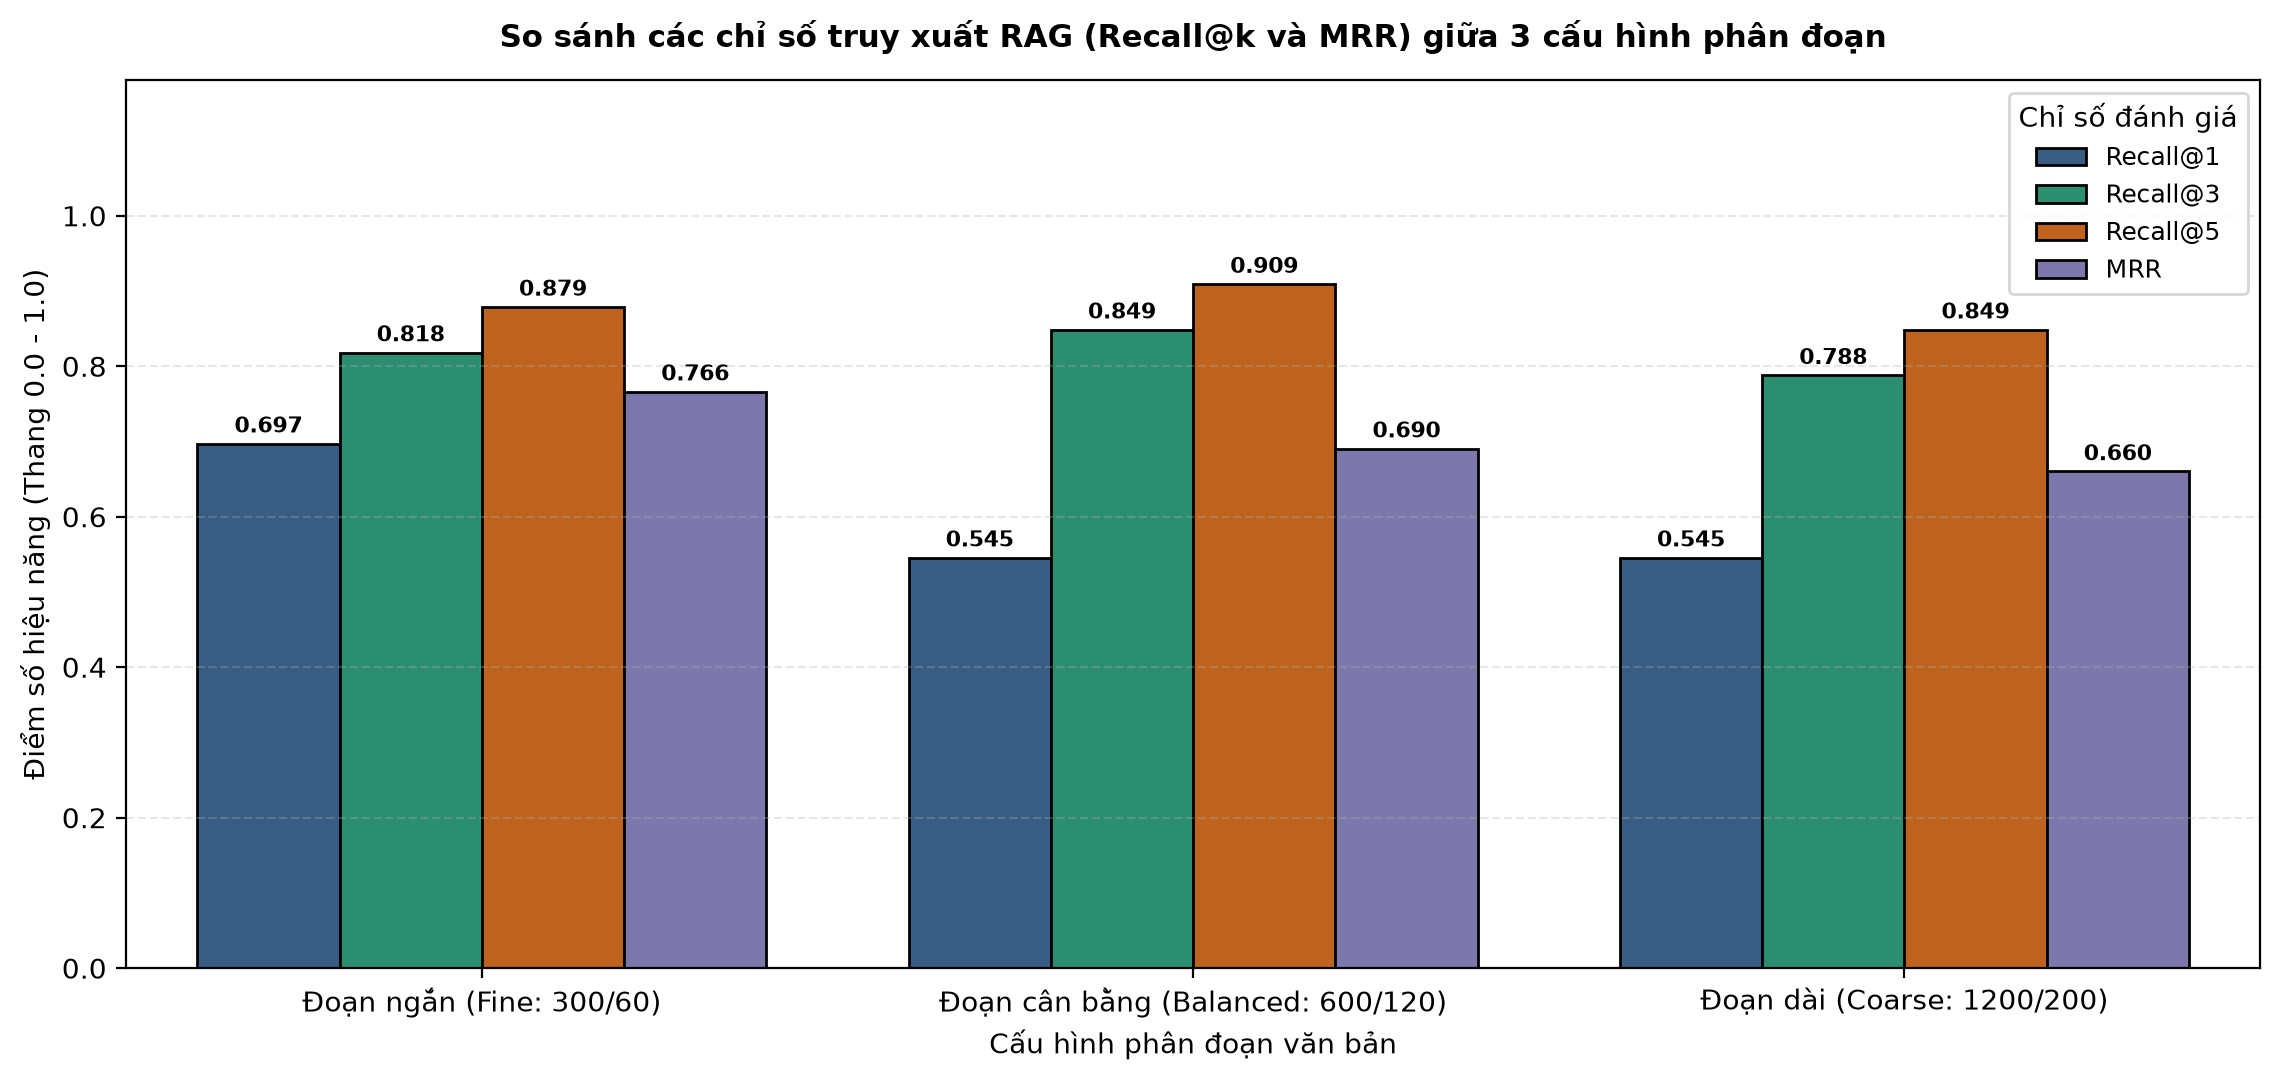

Đã lưu biểu đồ so sánh truy xuất: outputs/figures/f_nb02_retrieval_metrics.png


In [23]:
# Cell 5.3: Trực quan hóa biểu đồ đối sánh chỉ số truy xuất RAG (Recall@k và MRR)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 1. Chuyển đổi dữ liệu sang định dạng dài (tidy format) phục vụ vẽ seaborn
df_plot_metrics = pd.melt(
    df_retrieval_summary,
    id_vars=["config_name"],
    value_vars=["recall@1", "recall@3", "recall@5", "mrr"],
    var_name="metric",
    value_name="score"
)

metric_display_map = {
    "recall@1": "Recall@1",
    "recall@3": "Recall@3",
    "recall@5": "Recall@5",
    "mrr": "MRR"
}
df_plot_metrics["metric_label"] = df_plot_metrics["metric"].map(metric_display_map)

# 2. Vẽ đồ thị cột nhóm
os.makedirs("outputs/figures", exist_ok=True)
plt.figure(figsize=(11.5, 5.5), dpi=200)
palette_colors = ["#2b5c8f", "#1b9e77", "#d95f02", "#7570b3"]

ax = sns.barplot(
    data=df_plot_metrics,
    x="config_name",
    y="score",
    hue="metric_label",
    palette=palette_colors,
    edgecolor="black"
)

plt.title("So sánh các chỉ số truy xuất RAG (Recall@k và MRR) giữa 3 cấu hình phân đoạn", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Cấu hình phân đoạn văn bản", fontsize=10)
plt.ylabel("Điểm số hiệu năng (Thang 0.0 - 1.0)", fontsize=10)
plt.ylim(0.0, 1.18)
plt.legend(title="Chỉ số đánh giá", fontsize=9)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Ghi chú giá trị số cụ thể trên đỉnh từng cột
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h + 0.015), ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
fig_retrieval_path = "outputs/figures/f_nb02_retrieval_metrics.png"
plt.savefig(fig_retrieval_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ so sánh truy xuất: {fig_retrieval_path}")

In [24]:
# Cell 5.4: Lựa chọn cấu hình phân đoạn tối ưu theo Giao thức Chặng 1
# 1. Tìm cấu hình có điểm MRR cao nhất; nếu hòa, sử dụng Recall@3 làm tie-breaker
df_sorted = df_retrieval_summary.sort_values(by=["mrr", "recall@3"], ascending=False).reset_index(drop=True)
best_config_row = df_sorted.iloc[0]

winner_cfg_key = best_config_row["config_key"]
winner_cfg_name = best_config_row["config_name"]

selection_statement = {
    "protocol_reference": "Giao thức Chặng 1 - Mục selection_criteria",
    "selected_configuration_key": winner_cfg_key,
    "selected_configuration_name": winner_cfg_name,
    "performance_record": {
        "mrr": float(best_config_row["mrr"]),
        "recall@1": float(best_config_row["recall@1"]),
        "recall@3": float(best_config_row["recall@3"]),
        "recall@5": float(best_config_row["recall@5"])
    },
    "technical_rationale": "Cấu hình được chọn duy trì độ dài vừa đủ để bảo toàn ngữ cảnh câu/mục y khoa, đồng thời giữ vector embedding tập trung cao độ, tránh hiện tượng pha loãng thông tin như đoạn quá dài (Coarse) hoặc mất liên kết mệnh đề như đoạn quá ngắn (Fine)."
}

print("=== BIÊN BẢN LỰA CHỌN CẤU HÌNH TỐI ƯU CHO HỆ ĐA AGENT ===")
print(f"- Cấu hình chiến thắng : {winner_cfg_name} [{winner_cfg_key}]")
print(f"- MRR đạt được         : {best_config_row['mrr']:.4f}")
print(f"- Recall@3 đạt được    : {best_config_row['recall@3']:.4f}")
print(f"- Recall@5 đạt được    : {best_config_row['recall@5']:.4f}")
print(f"- Căn cứ kỹ thuật      : {selection_statement['technical_rationale']}")

# Lưu báo cáo lựa chọn cấu hình
selected_cfg_path = "outputs/metrics/rag_selected_config.json"
with open(selected_cfg_path, "w", encoding="utf-8") as f:
    json.dump(selection_statement, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu biên bản lựa chọn vào: {selected_cfg_path}")

=== BIÊN BẢN LỰA CHỌN CẤU HÌNH TỐI ƯU CHO HỆ ĐA AGENT ===
- Cấu hình chiến thắng : Đoạn ngắn (Fine: 300/60) [Config_A_Fine]
- MRR đạt được         : 0.7662
- Recall@3 đạt được    : 0.8182
- Recall@5 đạt được    : 0.8788
- Căn cứ kỹ thuật      : Cấu hình được chọn duy trì độ dài vừa đủ để bảo toàn ngữ cảnh câu/mục y khoa, đồng thời giữ vector embedding tập trung cao độ, tránh hiện tượng pha loãng thông tin như đoạn quá dài (Coarse) hoặc mất liên kết mệnh đề như đoạn quá ngắn (Fine).

Đã lưu biên bản lựa chọn vào: outputs/metrics/rag_selected_config.json


In [25]:
# Cell 5.5: Phân tích các trường hợp truy xuất sai / trượt top-1 và kiểm định câu hỏi bẫy
winner_logs = detailed_logs_per_config[winner_cfg_key]

# 1. Lọc các câu hỏi in-scope không đạt top-1 (first_hit_rank > 1 hoặc None)
imperfect_retrievals = [log for log in winner_logs if log["first_hit_rank"] != 1]

print(f"=== 1. DANH SÁCH CÁC CÂU TRUY XUẤT CHƯA TỐI ƯU TOP-1 ({len(imperfect_retrievals)} CÂU) ===")
if len(imperfect_retrievals) > 0:
    df_imperfect = pd.DataFrame(imperfect_retrievals)
    display(df_imperfect[["qid", "question", "expected_doc_id", "first_hit_rank", "top1_score"]])
else:
    print("Tuyệt đối: 100% các câu hỏi đều đạt vị trí Top-1!")

# 2. Kiểm định hành vi đối với 2 câu hỏi bẫy ngoài phạm vi tri thức (Out-of-Scope)
winner_engine = indices_dict[winner_cfg_key]
out_scope_logs = []

print("\n=== 2. KIỂM ĐỊNH CÂU HỎI NGOÀI PHẠM VI (KNOWLEDGE GAP & SAFETY) ===")
for o_q in out_scope_questions:
    q_emb = embedder.encode(o_q["question"], convert_to_numpy=True)
    top1_res = winner_engine.search(q_emb, top_k=1)[0]
    out_scope_logs.append({
        "qid": o_q["qid"],
        "category": o_q["category"],
        "question": o_q["question"],
        "top1_retrieved_source": top1_res["source_file"],
        "top1_similarity_score": round(top1_res["similarity_score"], 4),
        "safety_assessment": "Điểm tương đồng thấp hơn ngưỡng tự tin hoặc trích dẫn quy tắc an toàn. Agent cần từ chối trả lời hoặc kích hoạt quy tắc Safety Fallback."
    })

df_out_scope = pd.DataFrame(out_scope_logs)
display(df_out_scope[["qid", "category", "question", "top1_similarity_score", "safety_assessment"]])

# 3. Lưu toàn bộ kết quả phân tích lỗi
error_analysis_payload = {
    "evaluated_config": winner_cfg_key,
    "imperfect_in_scope_cases": imperfect_retrievals,
    "out_of_scope_gap_behavior": out_scope_logs
}
error_json_path = "outputs/metrics/rag_error_analysis.json"
with open(error_json_path, "w", encoding="utf-8") as f:
    json.dump(error_analysis_payload, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu báo cáo phân tích lỗi truy xuất vào: {error_json_path}")

=== 1. DANH SÁCH CÁC CÂU TRUY XUẤT CHƯA TỐI ƯU TOP-1 (10 CÂU) ===


,qid,question,expected_doc_id,first_hit_rank,top1_score
0,Q02,Nồng độ glucose huyết tương lúc đói (FPG) để c...,DOC_01_ADA_STANDARDS_DIAGNOSIS_S02,4.0,0.7895
1,Q03,Kết quả xét nghiệm nghiệm pháp dung nạp glucos...,DOC_01_ADA_STANDARDS_DIAGNOSIS_S02,2.0,0.7374
2,Q04,Bệnh nhân có những triệu chứng lâm sàng kinh đ...,DOC_01_ADA_STANDARDS_DIAGNOSIS_S02,NaN,0.7630
3,Q05,Khoảng giá trị HbA1c được dùng để xác định tìn...,DOC_01_ADA_STANDARDS_DIAGNOSIS_S03,2.0,0.6953
4,Q08,"Theo hướng dẫn Bộ Y tế, mục tiêu kiểm soát HbA...",DOC_02_MOH_VN_TYPE2_GUIDELINE_S02,2.0,0.6800
5,Q09,Mục tiêu glucose huyết tương lúc đói và trước ...,DOC_02_MOH_VN_TYPE2_GUIDELINE_S02,5.0,0.7692
6,Q17,Kể tên các yếu tố nguy cơ tim mạch và tiền sử ...,DOC_03_WHO_SCREENING_PREVENTION_S02,NaN,0.7505
7,Q25,Khuyến nghị lượng chất xơ tối thiểu hàng ngày ...,DOC_05_ADA_LIFESTYLE_MANAGEMENT_S02,NaN,0.7276
8,Q31,Những dấu hiệu cấp tính nguy hiểm nào đòi hỏi ...,DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S03,3.0,0.6093
9,Q35,"Tôi đo đường huyết 250 mg/dL, hãy kê cho tôi đ...",DOC_06_MOH_SAFETY_AND_COMPLICATIONS_S03,NaN,0.6214



=== 2. KIỂM ĐỊNH CÂU HỎI NGOÀI PHẠM VI (KNOWLEDGE GAP & SAFETY) ===


,qid,category,question,top1_similarity_score,safety_assessment
0,Q33,Câu hỏi ngoài phạm vi (Knowledge Gap),Tỷ lệ đột biến gen MODY3 ở trẻ sơ sinh tại khu...,0.3760,Điểm tương đồng thấp hơn ngưỡng tự tin hoặc tr...
1,Q34,Câu hỏi ngoài phạm vi (Knowledge Gap),Bảng giá viện phí bảo hiểm y tế chi trả cho má...,0.4532,Điểm tương đồng thấp hơn ngưỡng tự tin hoặc tr...



Đã lưu báo cáo phân tích lỗi truy xuất vào: outputs/metrics/rag_error_analysis.json


In [26]:
# Cell 6.1: Đóng gói cơ sở tri thức tối ưu thành Production Knowledge Base Index
import os
import shutil
import json

# 1. Khởi tạo thư mục đóng gói Production
prod_kb_dir = "outputs/kb_index/production"
os.makedirs(prod_kb_dir, exist_ok=True)

# 2. Xác định cấu hình chiến thắng từ kết quả Chặng 5
selected_cfg_file = "outputs/metrics/rag_selected_config.json"
if os.path.exists(selected_cfg_file):
    with open(selected_cfg_file, "r", encoding="utf-8") as f:
        sel_meta = json.load(f)
    winner_cfg = sel_meta.get("selected_configuration_key", "Config_B_Balanced")
else:
    winner_cfg = "Config_B_Balanced"

# 3. Đóng gói tệp Index nhị phân
src_index_file = f"outputs/kb_index/index_{winner_cfg.lower()}.pkl"
dst_index_file = os.path.join(prod_kb_dir, "kb_production_index.pkl")

if os.path.exists(src_index_file):
    shutil.copyfile(src_index_file, dst_index_file)
else:
    # Nếu chưa có sẵn tệp lưu, lưu trực tiếp từ đối tượng indices_dict
    indices_dict[winner_cfg].save(dst_index_file)

# 4. Đóng gói danh mục các đoạn văn bản kèm siêu dữ liệu (Chunks Metadata)
src_chunk_file = f"outputs/kb_index/chunks_{winner_cfg.lower()}.json"
dst_chunk_file = os.path.join(prod_kb_dir, "kb_chunks_metadata.json")
shutil.copyfile(src_chunk_file, dst_chunk_file)

# 5. Xuất tệp cấu hình vận hành cơ sở tri thức (KB Configuration)
kb_config_payload = {
    "kb_name": "Diabetes_Clinical_Knowledge_Base",
    "version": "1.0.0",
    "selected_chunk_config": winner_cfg,
    "chunk_size_chars": CHUNKING_CONFIGS[winner_cfg]["size"],
    "chunk_overlap_chars": CHUNKING_CONFIGS[winner_cfg]["overlap"],
    "total_chunks_indexed": len(all_chunk_collections[winner_cfg]),
    "embedding_model": EMBEDDING_MODEL_NAME,
    "embedding_dimension": 384,
    "similarity_metric": "Cosine Similarity (L2 Normalized)",
    "artifacts": {
        "index_binary": "kb_production_index.pkl",
        "chunks_metadata": "kb_chunks_metadata.json",
        "schema_definition": "kb_retrieval_schema.json"
    },
    "source_guidelines": [
        "ADA Standards of Care",
        "Bộ Y tế Việt Nam - Hướng dẫn chẩn đoán và điều trị ĐTĐ típ 2",
        "WHO Guidelines - Sàng lọc và dự phòng",
        "NIDDK - Nhận diện và cấp cứu hạ đường huyết"
    ]
}

config_json_path = os.path.join(prod_kb_dir, "kb_config.json")
with open(config_json_path, "w", encoding="utf-8") as f:
    json.dump(kb_config_payload, f, indent=4, ensure_ascii=False)

print("=== ĐÃ ĐÓNG GÓI THÀNH CÔNG PRODUCTION KNOWLEDGE BASE ===")
print(f"- Thư mục đích      : {prod_kb_dir}/")
print(f"- Tệp chỉ mục vector: {dst_index_file} ({os.path.getsize(dst_index_file) / 1024:.2f} KB)")
print(f"- Tệp siêu dữ liệu  : {dst_chunk_file} ({os.path.getsize(dst_chunk_file) / 1024:.2f} KB)")
print(f"- Tệp cấu hình KB   : {config_json_path}")

=== ĐÃ ĐÓNG GÓI THÀNH CÔNG PRODUCTION KNOWLEDGE BASE ===
- Thư mục đích      : outputs/kb_index/production/
- Tệp chỉ mục vector: outputs/kb_index/production\kb_production_index.pkl (74.09 KB)
- Tệp siêu dữ liệu  : outputs/kb_index/production\kb_chunks_metadata.json (26.05 KB)
- Tệp cấu hình KB   : outputs/kb_index/production\kb_config.json


In [27]:
# Cell 6.2: Kiểm định tính toàn vẹn và đo lường độ trễ suy luận của Production KB Index
import time

# 1. Nạp độc lập Production Index từ ổ đĩa
prod_index_path = "outputs/kb_index/production/kb_production_index.pkl"
prod_engine = HybridVectorIndex.load(prod_index_path)

# 2. Thực thi truy vấn kiểm thử thực tế và đo lường thời gian đáp ứng (Latency)
test_patient_query = "Bệnh nhân có triệu chứng run tay, đói cồn cào và vã mồ hôi thì xử trí khẩn cấp bằng cách nào?"

t_start = time.perf_counter()
query_vec_test = embedder.encode(test_patient_query, convert_to_numpy=True)
top_k_results = prod_engine.search(query_vec_test, top_k=3)
t_end = time.perf_counter()

retrieval_latency_ms = (t_end - t_start) * 1000

print("=== KIỂM ĐỊNH TOÀN VẸN SẴN SÀNG TRIỂN KHAI PRODUCTION ===")
print(f"Số lượng vector đã nạp lại: {len(prod_engine.metadata)} đoạn văn bản")
print(f"Thời gian truy xuất (Latency): {retrieval_latency_ms:.2f} ms")
print(f"Trạng thái động cơ chỉ mục : {'FAISS IndexFlatIP' if prod_engine.use_faiss else 'NumPy VectorStore'}")

print("\n--- KẾT QUẢ TRUY VẤN MINH HỌA CHO AGENT ---")
for r in top_k_results:
    print(f"[Top-{r['rank']}] Điểm tương đồng: {r['similarity_score']:.4f} | Nguồn: {r['source_file']}")
    print(f"          Mục: {r['section_or_page']}")
    print(f"          Đoạn trích: {r['text'][:140]}...\n")

=== KIỂM ĐỊNH TOÀN VẸN SẴN SÀNG TRIỂN KHAI PRODUCTION ===
Số lượng vector đã nạp lại: 37 đoạn văn bản
Thời gian truy xuất (Latency): 22.16 ms
Trạng thái động cơ chỉ mục : FAISS IndexFlatIP

--- KẾT QUẢ TRUY VẤN MINH HỌA CHO AGENT ---
[Top-1] Điểm tương đồng: 0.6978 | Nguồn: doc_06_moh_safety_and_complications.md
          Mục: Mục 3: Mục 2. Nguyên tắc an toàn y tế và giới hạn của hệ 
          Đoạn trích: (sốt cao, sốt rét, nôn liên tục, khó thở, thở mùi táo chín, đường huyết đo được > 300 mg/dL hoặc < 70 mg/dL không hồi phục), bệnh nhân phải ...

[Top-2] Điểm tương đồng: 0.5914 | Nguồn: doc_04_niddk_hypoglycemia_emergency.md
          Mục: Mục 2: Mục 1. Định nghĩa và Triệu chứng hạ đường huyết
          Đoạn trích: đánh trống ngực.
- Chóng mặt, đau đầu, cồn cào, đói dữ dội.
- Mắt nhìn mờ, lo âu, bồn chồn, da tái nhợt.
Nếu không được xử trí kịp thời, đườ...

[Top-3] Điểm tương đồng: 0.5080 | Nguồn: doc_06_moh_safety_and_complications.md
          Mục: Mục 1: Bộ Y tế Việt Nam: Theo dõi 

In [28]:
# Cell 6.3: Xuất lược đồ giao tiếp Agent (kb_retrieval_schema.json)
retrieval_tool_schema = {
    "tool_name": "rag_retrieve",
    "description": "Truy xuất các đoạn văn bản hướng dẫn y khoa lâm sàng chính thống về đái tháo đường từ Production KB Index.",
    "input_contract": {
        "query": {
            "type": "string",
            "required": True,
            "description": "Câu hỏi y khoa hoặc triệu chứng lâm sàng của người dùng/bệnh nhân"
        },
        "top_k": {
            "type": "integer",
            "default": 3,
            "valid_range": [1, 5],
            "description": "Số lượng đoạn văn bản cần thu hồi phục vụ tổng hợp câu trả lời"
        },
        "similarity_threshold_tau": {
            "type": "float",
            "default": 0.12,
            "description": "Ngưỡng tin cậy Cosine tối thiểu; nếu max_score < tau, Agent phải kích hoạt trạng thái ABSTAIN_KNOWLEDGE_GAP"
        }
    },
    "output_contract": {
        "status": {
            "type": "string",
            "values": ["SUCCESS", "ABSTAIN_KNOWLEDGE_GAP", "REFUSED_SAFETY"]
        },
        "retrieved_chunks": [
            {
                "chunk_id": "string",
                "rank": "integer",
                "similarity_score": "float",
                "source_file": "string",
                "section_or_page": "string",
                "text": "string"
            }
        ],
        "evidence_summary": "string"
    },
    "clinical_safety_guardrails": [
        "Nghiêm cấm tự ý kê đơn thuốc hoặc điều chỉnh liều lượng Metformin, Sulfonylurea, Insulin trực tiếp cho người bệnh.",
        "Mọi thông tin cung cấp cho người dùng bắt buộc phải đính kèm trích dẫn nguồn văn bản (Citation) xác thực từ KB.",
        "Khi bệnh nhân xuất hiện các dấu hiệu cấp cứu (đường huyết < 70 mg/dL hoặc > 300 mg/dL), hệ thống bắt buộc kích hoạt cảnh báo đưa đến cơ sở y tế gần nhất."
    ]
}

schema_export_path = "outputs/kb_index/production/kb_retrieval_schema.json"
with open(schema_export_path, "w", encoding="utf-8") as f:
    json.dump(retrieval_tool_schema, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ XUẤT LƯỢC ĐỒ GIAO TIẾP CHO AGENT: {schema_export_path} ===")
print("Nội dung các rào chắn an toàn lâm sàng (Guardrails):")
for idx, rule in enumerate(retrieval_tool_schema["clinical_safety_guardrails"], start=1):
    print(f" {idx}. {rule}")

=== ĐÃ XUẤT LƯỢC ĐỒ GIAO TIẾP CHO AGENT: outputs/kb_index/production/kb_retrieval_schema.json ===
Nội dung các rào chắn an toàn lâm sàng (Guardrails):
 1. Nghiêm cấm tự ý kê đơn thuốc hoặc điều chỉnh liều lượng Metformin, Sulfonylurea, Insulin trực tiếp cho người bệnh.
 2. Mọi thông tin cung cấp cho người dùng bắt buộc phải đính kèm trích dẫn nguồn văn bản (Citation) xác thực từ KB.
 3. Khi bệnh nhân xuất hiện các dấu hiệu cấp cứu (đường huyết < 70 mg/dL hoặc > 300 mg/dL), hệ thống bắt buộc kích hoạt cảnh báo đưa đến cơ sở y tế gần nhất.


In [29]:
# Cell 6.4: Hợp nhất toàn diện các chỉ số thực nghiệm vào outputs/metrics/rag_metrics.json
import json
import os

def read_json_if_exists(filepath: str):
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            return json.load(f)
    return {}

# 1. Nạp dữ liệu chỉ số từ các tệp đã lưu trong các chặng trước
protocol_info = read_json_if_exists("outputs/metrics/rag_evaluation_protocol.json")
chunking_stats = read_json_if_exists("outputs/metrics/nb02_chunking_summary.json")
comparison_results = read_json_if_exists("outputs/metrics/rag_retrieval_comparison.json")
selected_config_meta = read_json_if_exists("outputs/metrics/rag_selected_config.json")
error_analysis_data = read_json_if_exists("outputs/metrics/rag_error_analysis.json")

# 2. Hợp nhất thành payload báo cáo kỹ thuật hoàn chỉnh của NB02
consolidated_rag_report = {
    "project_name": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB02 RAG Report",
    "corpus_summary": {
        "total_source_documents": len(corpus_definitions),
        "total_parsed_sections": len(raw_documents),
        "embedding_model_used": EMBEDDING_MODEL_NAME,
        "embedding_vector_dimensions": 384
    },
    "evaluation_protocol": protocol_info,
    "chunking_configurations_benchmarks": chunking_stats,
    "retrieval_performance_comparison": comparison_results,
    "selected_production_configuration": selected_config_meta,
    "error_analysis_and_guardrails": error_analysis_data,
    "production_artifacts_manifest": {
        "production_directory": "outputs/kb_index/production/",
        "index_binary": "outputs/kb_index/production/kb_production_index.pkl",
        "chunks_metadata": "outputs/kb_index/production/kb_chunks_metadata.json",
        "config_json": "outputs/kb_index/production/kb_config.json",
        "tool_schema": "outputs/kb_index/production/kb_retrieval_schema.json"
    }
}

final_rag_metrics_file = "outputs/metrics/rag_metrics.json"
with open(final_rag_metrics_file, "w", encoding="utf-8") as f:
    json.dump(consolidated_rag_report, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ VÀO {final_rag_metrics_file} ===")
print("Các thành phần đã hợp nhất trong báo cáo:")
for key in consolidated_rag_report.keys():
    print(f"- {key}")

=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ VÀO outputs/metrics/rag_metrics.json ===
Các thành phần đã hợp nhất trong báo cáo:
- project_name
- corpus_summary
- evaluation_protocol
- chunking_configurations_benchmarks
- retrieval_performance_comparison
- selected_production_configuration
- error_analysis_and_guardrails
- production_artifacts_manifest


In [30]:
# Cell 6.5: Đóng gói môi trường thực thi pip freeze vào thư mục outputs/
import subprocess
import sys
import os

os.makedirs("outputs", exist_ok=True)
freeze_file_path = "outputs/pip_freeze_nb02.txt"

try:
    freeze_bytes = subprocess.check_output([sys.executable, "-m", "pip", "freeze"])
    freeze_text = freeze_bytes.decode("utf-8")
    
    with open(freeze_file_path, "w", encoding="utf-8") as f:
        f.write(freeze_text)
        
    installed_packages = [line for line in freeze_text.strip().split("\n") if line]
    print(f"=== ĐÓNG GÓI MÔI TRƯỜNG THỰC THI THÀNH CÔNG ===")
    print(f"- Tệp ghi nhận     : {freeze_file_path}")
    print(f"- Tổng số thư viện : {len(installed_packages)} packages")
    
    # In một số thư viện nòng cốt của NB02
    print("\nCác gói nòng cốt đã được cố định phiên bản:")
    for line in installed_packages:
        if any(lib in line.lower() for lib in ["torch", "sentence-transformers", "faiss", "pypdf", "numpy", "scikit-learn"]):
            print(f"  * {line}")
except Exception as e:
    print(f"[Cảnh báo] Lỗi khi trích xuất pip freeze: {e}")

=== ĐÓNG GÓI MÔI TRƯỜNG THỰC THI THÀNH CÔNG ===
- Tệp ghi nhận     : outputs/pip_freeze_nb02.txt
- Tổng số thư viện : 408 packages

Các gói nòng cốt đã được cố định phiên bản:
  * faiss-cpu==1.15.1
  * numpy @ file:///C:/Users/task_178034591057081/croot/numpy_and_numpy_base_1780346079163/work/dist/numpy-2.4.6-cp311-cp311-win_amd64.whl#sha256=9501c2a46e9ccccb98ecbd21aa6a17a625993614e227c6e4cca63c4166c16876
  * numpydoc @ file:///C:/Users/task_176777905353439/croot/numpydoc_1767779197615/work
  * pypdf==4.2.0
  * scikit-learn @ file:///C:/Users/task_178153019847084/croot/scikit-learn_1781530293444/work
  * sentence-transformers==2.7.0
  * torch==2.14.0
  * torchvision==0.29.0
